# Budget-Aware Retrieval-Augmented Fact-Checking for Malay and Vietnamese

Code and outputs for the paper *Budget-Aware Retrieval-Augmented Fact-Checking for Malay and Vietnamese: A Pre-Registered Benchmark of Evidence Retrieval, Early-Exit Re-Ranking, and Verdict Prediction* (Ibrahim Mohd Jamadi and Syahid Anuar, Faculty of Artificial Intelligence, Universiti Teknologi Malaysia).

The notebook builds the Southeast Asian Fact-checking Benchmark (SEAFact-Bench) from openly downloadable datasets and runs every experiment reported in the paper. The outputs shown are those of the registered run (pre-registration SHA-256 `705661ed59fa21f22f4d62070131c95cd94d1dd0eb108de4fc637dc99db74cfa`, one NVIDIA RTX PRO 6000 Blackwell GPU in Google Colab). The final section, an exploratory diagnosis, was run afterwards from the cached stages of the same run and uses development claims only.

| Role | Dataset | Language(s) | Used for |
|---|---|---|---|
| Target and source | SEBENARNYA-Fact v1.0 | Malay (`ms`) | retrieval, re-ranking, verdicts |
| Target and source | ViFactCheck (`tranthaihoa/vifactcheck`) | Vietnamese (`vi`) | retrieval, re-ranking, verdicts |
| Verdicts only | X-FACT (`utahnlp/x-fact`) | Indonesian, Hindi, Bengali, Tamil | verdicts with the released evidence snippets |
| Source only | SciFact (BEIR) | English (`en`) | additional training data for the re-ranking cascade |

**Pipeline.** Claim → first-stage retrieval (BM25, BGE-M3, multilingual-E5, Qwen3-Embedding, hybrid) → cross-encoder re-ranking under a compute budget *B* (Fixed depth, FixedResidual, Current Rank, Boundary, Random, Patience, SEE, GAINER, full depth) → verdict model (fine-tuned XLM-R, Qwen2.5-7B-Instruct zero- and three-shot) → *Supports*, *Refutes*, *Context* or abstain.

**Protocol.** Pre-registration file with SHA-256 digest; temporal split for SEBENARNYA-Fact (test claims published on or after 2025-01-01); leave-one-language-out training of exit heads and rankers, with English SciFact always a source; five seeds; leak test and conditional-execution latency; paired sign-flip and swap randomisation tests, stratified bootstrap confidence intervals, Holm correction, and a non-inferiority test for H5.

### Running the notebook
1. Select a GPU runtime. BGE-reranker-v2-m3 in 32-bit precision and the 7B model in 4-bit precision need a GPU with at least 24 GB of memory (L4, A100 or newer).
2. Run the installation cell and restart the session if Colab asks for it.
3. With `dry_run=True`, every stage runs on small samples, the test split is withheld (half of each development split stands in for it), and results go to `dry_run/`. With `dry_run=False`, the registered configuration runs and results go to `full_run/`.
4. With `USE_DRIVE=True`, every stage is cached in Google Drive, so an interrupted run resumes from the last completed stage.

### Notebook outputs and the paper
| Notebook output (`run_dir/tables/`) | Paper |
|---|---|
| `table3_label_mapping` | Table II |
| `table2_benchmark`, `pool_recall50` | Table III |
| `table4_hypotheses_results` | Table V |
| `table5_retrieval`, `table5b_retrieval_low_overlap`, `table5s_*`, `table5d_retrieval_dev` | Table VI |
| `table6_rerank_*`, `latency` | Table VII |
| `fig2_*` | Fig. 2 |
| `exit_head_quality` | Fig. 3 |
| `exploratory/exploratory_summary` | Table VIII |
| `table7_verdict`, `table7c_evidence_k` | Table IX |
| `table7b_verdict_by_language` | Table X |
| `table8_end_to_end`, `table8b_verdict_gainer_vs_currentrank` | Table XI, Fig. 4 |
| `table9_abstention`, `table9b_abstention_by_language` | Table XII |
| `leak_test`, `conditional_execution_check` | Section VI-B |

Per-query results for every retriever, policy, seed and budget are written next to the tables.

In [61]:
# Package versions of the reported run (Colab provides torch, numpy, pandas, scipy and matplotlib).
!pip -q install "transformers==4.52.4" "sentence-transformers==4.1.0" "accelerate==1.7.0" "datasets>=2.19,<4" "huggingface_hub>=0.30,<1.0" "bitsandbytes>=0.45" pyarrow tqdm tabulate

In [62]:
USE_DRIVE = True   # keep caches and results in Google Drive
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

Mounted at /content/drive


In [63]:
import os, re, json, math, time, random, hashlib, pickle, gc, warnings, zipfile, unicodedata, copy, datetime
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="transformers")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cuda.matmul.allow_tf32 = False   # exact fp32 replay for the conditional-execution check
torch.backends.cudnn.allow_tf32 = False
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

CFG = dict(
    # ---- run control ----
    out_dir="/content/drive/MyDrive/seafact_runs" if USE_DRIVE else "/content/seafact_runs",
    dry_run=False,                 # True: small samples, 1 seed, fewer permutations. Set False for the registered run.
    dry_run_queries=60,           # queries per (language, split) in a dry run
    dry_run_pool_cap=None,        # None = full evidence pools also in a dry run (needed for a meaningful re-ranker check)
    seeds=[0, 1, 2, 3, 4],
    allow_prereg_change=False,    # the full run refuses to start if the registered settings were changed

    # ---- open datasets ----
    sebenarnya_hf="ibrahimjamadi/SEBENARNYA-Fact",
    sebenarnya_csv_url="https://raw.githubusercontent.com/ibrahimjamadi98/SEBENARNYA-Fact/main/data/SEBENARNYA_Fact_Dataset_v1.0.csv",
    sebenarnya_local_csv=None,    # optional path to a local copy of the CSV
    vifactcheck_hf="tranthaihoa/vifactcheck",
    xfact_hf="utahnlp/x-fact",
    xfact_languages=["id", "hi", "bn", "ta"],
    scifact_hf="BeIR/scifact", scifact_qrels_hf="BeIR/scifact-qrels", scifact_fallback_hf="mteb/scifact",
    use_scifact_source=True,

    # ---- benchmark construction ----
    temporal_cutoff="2025-01-01",  # SEBENARNYA test = published on or after this date
    dev_fraction=0.10,             # last 10% of the SEBENARNYA training period (by date) is dev
    min_evidence_chars=50,
    low_overlap_quantile=0.25,
    n_nomatch=200,                 # test claims per target language with the gold evidence removed
    abstention_dev_cap=300,        # dev claims per language used only to set abstention thresholds
    paraphrase_csv=None,           # optional CSV with columns qid,paraphrase (written by native speakers)

    # ---- first-stage retrieval ----
    dense_models={
        "BGE-M3": "BAAI/bge-m3",
        "multilingual-E5": "intfloat/multilingual-e5-large",
        "Qwen3-Embedding-0.6B": "Qwen/Qwen3-Embedding-0.6B",
    },
    dense_max_len=512, dense_batch=32,
    hybrid_dense="BGE-M3", hybrid_weight=0.5,
    run_depth=100, candidates_k=50,
    bm25_k1=1.5, bm25_b=0.75,
    finetune_dense=True,
    finetune=dict(model="BGE-M3", epochs=1, batch=16, lr=1e-5, max_len=256, warmup_ratio=0.1),

    # ---- cross-encoder backbones and GAINER ----
    backbones={
        # main backbone (568M parameters, 24 layers; 32-bit precision as in the original GAINER study; A100/L4/Blackwell recommended)
        "BGE-reranker-v2-m3": dict(hf="BAAI/bge-reranker-v2-m3", checkpoints=[4, 8, 12, 16, 20, 24], batch=50, dtype="float32"),
        # replication backbone (small, 12 layers)
        "mMiniLM-L12": dict(hf="cross-encoder/mmarco-mMiniLMv2-L12-H384-v1", checkpoints=[2, 4, 6, 8, 10, 12], batch=50, dtype="float32"),
    },
    primary_backbone="BGE-reranker-v2-m3",
    ce_max_len=384, cls_dtype="float16",
    ce_doc_text="best_passage",    # cross-encoder input: "best_passage" (best ce_passage_words window by claim overlap) or "full" (first ce_max_len tokens)
    ce_passage_words=200,
    budgets=[0.25, 0.35, 0.5, 0.65, 0.8, 1.0], primary_budget=0.5,
    train_budgets=[0.25, 0.35, 0.5, 0.65, 0.8],
    source_query_cap=600, holdout_fraction=0.2,
    # learned components: same settings as the original GAINER implementation
    head_hidden=160, head_dropout=0.1, weight_decay=1e-4,
    head_lr=2e-3, head_epochs=25, head_batch=512, head_patience=5,      # exit heads
    lr=1e-3, ranker_epochs=30, batch=4096, patience=6,                  # per-transition rankers
    patience_p=1,                                                       # Patience baseline: stable checkpoints before exit
    pairs_per_group=32, max_pairs_per_transition=300_000, dagger_rounds=1,
    leak_test_queries=50,
    run_latency=True, latency_queries=40, latency_warmup=5, latency_repeats=3,

    # ---- verdict models ----
    classifier_hf="xlm-roberta-large",
    clf=dict(epochs=3, batch=16, lr=1e-5, max_len=256, warmup=0.1, weight_decay=0.01, evidence_dropout=0.15),
    run_llm=True,
    llms={"Qwen2.5-7B-Instruct": "Qwen/Qwen2.5-7B-Instruct"},
    llm_4bit=True, llm_shots=[0, 3], llm_batch=4, llm_max_per_lang=300, llm_dev_per_lang=150,
    evidence_k=3, evidence_k_grid=[1, 3, 5], passage_words=120,
    primary_verdict_model="Qwen2.5-7B-Instruct",   # key of `llms`, or "XLM-R" for the fine-tuned classifier
    primary_llm_shots=3,                           # shots of the primary LLM (used when the primary verdict model is an LLM)
    e2e_all_claims=True,                           # primary LLM scored on ALL ms/vi test claims for H4, H5 and Table VIII (power for delta = 1 point)

    # ---- statistics ----
    n_permutations=100_000, n_permutations_f1=10_000, n_bootstrap=10_000,
    noninferiority_delta=1.0,       # macro-F1 points
    alpha=0.05,
    abstain_target_coverage=0.95, selective_coverage=0.80,
)


def finalize_cfg(cfg):
    c = copy.deepcopy(cfg)
    c["run_dir"] = os.path.join(c["out_dir"], "dry_run" if c["dry_run"] else "full_run")
    if c["dry_run"]:
        n = c["dry_run_queries"]
        c.update(seeds=c["seeds"][:1], n_permutations=2000, n_permutations_f1=500, n_bootstrap=500,
                 source_query_cap=n, n_nomatch=min(c["n_nomatch"], 20), abstention_dev_cap=min(c["abstention_dev_cap"], 30),
                 leak_test_queries=min(c["leak_test_queries"], 10), latency_queries=min(c["latency_queries"], 5),
                 latency_warmup=2, llm_max_per_lang=min(c["llm_max_per_lang"], 24), llm_dev_per_lang=min(c["llm_dev_per_lang"], 12))
        c["clf"] = dict(c["clf"], epochs=1)
        c["finetune"] = dict(c["finetune"], epochs=1)
    os.makedirs(os.path.join(c["run_dir"], "cache"), exist_ok=True)
    os.makedirs(os.path.join(c["run_dir"], "tables"), exist_ok=True)
    return c


C = finalize_cfg(CFG)
print("Run directory:", C["run_dir"], "| dry run:", C["dry_run"])

Device: cuda NVIDIA RTX PRO 6000 Blackwell Server Edition
Run directory: /content/drive/MyDrive/seafact_runs/full_run | dry run: False


## Pre-registration
The hypotheses, the primary configuration and the test procedures are written to `prereg.json` and hashed with SHA-256 before any test result is computed. In a full run, the notebook stops if the file already exists with a different hash; `allow_prereg_change=True` registers a new version.

In [64]:
PREREG = {
    "title": "Budget-Aware Retrieval-Augmented Fact-Checking for Southeast Asian Languages",
    "data": "Open datasets only: SEBENARNYA-Fact v1.0 (ms), ViFactCheck (vi), X-FACT id/hi/bn/ta (verdict only), SciFact (en, source only).",
    "hypotheses": {
        "H1": "Hybrid retrieval (BM25 + BGE-M3) beats the best single retriever (chosen on dev) in macro nDCG@10 over the ms and vi test sets.",
        "H2": "Fine-tuned BGE-M3 beats zero-shot BGE-M3 in nDCG@10 on the paraphrased subset (low-overlap subset if no paraphrases are supplied).",
        "H3": "Multilingual GAINER beats the score-based cascade (Current Rank) in macro nDCG@10 at B = 0.50 under leave-one-language-out training.",
        "H4": "Verdict macro-F1 of the primary verdict model is lower with retrieved evidence (full depth, k = 3) than with gold evidence.",
        "H5": "End-to-end verdict macro-F1 with GAINER at B = 0.50 is non-inferior to full depth within a margin of delta macro-F1 points.",
        "H6": "Multilingual GAINER beats SEE (exit before block 0, threshold calibrated on source languages) in macro nDCG@10 at B = 0.50 under leave-one-language-out training.",
    },
    "families": {"F1": ["H1", "H2", "H3", "H6"], "F2": ["H4", "H5"]},
    "tests": {
        "H1-H3, H6": "Two-sided paired sign-flip randomisation test stratified by language; statistic = macro (over languages) mean per-query difference; Holm within F1.",
        "H4": "Two-sided paired swap randomisation test on per-claim predictions; statistic = macro (over languages) difference in macro-F1; Holm within F2.",
        "H5": "Supported if the lower bound of the stratified bootstrap 95% CI of the macro-F1 difference (B = 0.50 minus full depth) lies above -delta.",
        "CI": "Stratified bootstrap (resampling claims within language).",
    },
    "primary": {k: C[k] for k in ["primary_backbone", "primary_budget", "primary_verdict_model", "primary_llm_shots", "e2e_all_claims", "noninferiority_delta",
                                  "temporal_cutoff", "evidence_k", "hybrid_dense", "hybrid_weight", "candidates_k"]},
    "settings": {k: CFG[k] for k in ["seeds", "budgets", "train_budgets", "source_query_cap", "holdout_fraction", "pairs_per_group",
                                     "max_pairs_per_transition", "dagger_rounds", "head_hidden", "head_lr", "head_batch", "head_epochs", "head_patience",
                                     "weight_decay", "lr", "batch", "ranker_epochs", "patience", "n_permutations",
                                     "ce_doc_text", "ce_passage_words",
                                     "n_permutations_f1", "n_bootstrap", "alpha", "abstain_target_coverage", "selective_coverage",
                                     "xfact_languages", "classifier_hf", "llms", "llm_shots", "llm_max_per_lang", "dense_models"]},
    "backbones": CFG["backbones"],
}


def write_preregistration(prereg, run_dir, allow_change=False, dry_run=True):
    body = json.dumps(prereg, sort_keys=True, ensure_ascii=False, indent=1)
    digest = hashlib.sha256(body.encode("utf-8")).hexdigest()
    path = os.path.join(run_dir, "prereg.json")
    if os.path.exists(path):
        old = json.load(open(path, encoding="utf-8"))
        if old["sha256"] != digest:
            msg = f"Pre-registration changed: registered {old['sha256'][:12]}..., current {digest[:12]}..."
            if dry_run or allow_change:
                print("WARNING:", msg, "(overwriting: dry run or allow_prereg_change=True)")
            else:
                raise RuntimeError(msg + " — refusing to run. Restore the registered settings or set allow_prereg_change=True and report the change.")
        else:
            print("Pre-registration unchanged:", digest)
            return digest
    record = {"sha256": digest, "registered_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(), "prereg": prereg}
    json.dump(record, open(path, "w", encoding="utf-8"), ensure_ascii=False, indent=1)
    open(os.path.join(run_dir, "prereg.sha256"), "w").write(digest + "\n")
    print("Pre-registration written:", path, "\nSHA-256:", digest)
    return digest


PREREG_HASH = write_preregistration(PREREG, C["run_dir"], C["allow_prereg_change"], C["dry_run"])

Pre-registration written: /content/drive/MyDrive/seafact_runs/full_run/prereg.json 
SHA-256: 705661ed59fa21f22f4d62070131c95cd94d1dd0eb108de4fc637dc99db74cfa


In [65]:
TOKEN_RE = re.compile(r"\w+", re.UNICODE)


def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def stable_id(text, n=12):
    return hashlib.sha1(str(text).encode("utf-8")).hexdigest()[:n]


def clean_text(s):
    if s is None or (isinstance(s, float) and math.isnan(s)):
        return ""
    s = unicodedata.normalize("NFC", str(s))
    return re.sub(r"\s+", " ", s).strip()


def tokenize(text, lang=None):
    return TOKEN_RE.findall(clean_text(text).lower())


def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / max(1, len(a | b))


def best_passage(text, claim, lang, words=None):
    words = words or C["passage_words"]
    toks = clean_text(text).split()
    if len(toks) <= words:
        return " ".join(toks)
    cset = set(tokenize(claim, lang))
    marks = np.array([float(any(t in cset for t in TOKEN_RE.findall(w.lower()))) for w in toks])
    cs = np.concatenate([[0.0], np.cumsum(marks)])
    starts = list(range(0, len(toks) - words + 1, 20))
    best = max(starts, key=lambda s: cs[s + words] - cs[s])
    return " ".join(toks[best:best + words])


CODE_VERSION = "seafact-nb-2026-10-12c"


def fingerprint(*keys, **extra):
    """Short hash of the settings a stage depends on: a cached stage is reused only if none of them changed."""
    d = {k: C.get(k) for k in keys}
    d.update(extra, _code=CODE_VERSION)
    return hashlib.sha1(json.dumps(d, sort_keys=True, default=str).encode()).hexdigest()[:10]


FP_BENCH = fingerprint("dry_run", "dry_run_queries", "dry_run_pool_cap", "temporal_cutoff", "dev_fraction", "min_evidence_chars",
                       "low_overlap_quantile", "n_nomatch", "abstention_dev_cap", "paraphrase_csv", "source_query_cap",
                       "xfact_languages", "use_scifact_source", "sebenarnya_local_csv")


def cache_file(name):
    return os.path.join(C["run_dir"], "cache", name)


def cached(name, fn, force=False):
    """Run fn() once and keep the result on disk; later calls (or a resumed session) load it."""
    path = cache_file(name + ".pkl")
    if os.path.exists(path) and not force:
        with open(path, "rb") as f:
            return pickle.load(f)
    out = fn()
    with open(path + ".tmp", "wb") as f:
        pickle.dump(out, f, protocol=4)
    os.replace(path + ".tmp", path)
    return out


def free_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def save_table(df, name, caption=""):
    tdir = os.path.join(C["run_dir"], "tables")
    df.to_csv(os.path.join(tdir, name + ".csv"), index=True)
    TABLES[name] = (caption, df)
    cap_path = os.path.join(tdir, "captions.json")
    caps = json.load(open(cap_path)) if os.path.exists(cap_path) else {}
    caps[name] = caption
    json.dump(caps, open(cap_path, "w"), indent=1)
    return df


def show_table(name):
    if name not in TABLES:
        path = os.path.join(C["run_dir"], "tables", name + ".csv")
        TABLES[name] = ("", pd.read_csv(path, index_col=0))
    display(TABLES[name][1])


TABLES = {}

In [66]:
UNIFIED = ["Supports", "Refutes", "Context"]
LAB2ID = {l: i for i, l in enumerate(UNIFIED)}

SEBENARNYA_MAP = {"false": "Refutes", "misleading": "Refutes", "true": "Supports",
                  "warning": "Context", "clarification": "Context"}
VIFACTCHECK_MAP = {0: "Supports", 1: "Refutes", 2: "Context"}   # 0 = Supported, 1 = Refuted, 2 = NEI


def xfact_unified(label):
    l = clean_text(label).lower()
    if l in ("true", "mostly true"):
        return "Supports"
    if l in ("false", "mostly false") or l.startswith("partly true") or l.startswith("half true") or "misleading" in l:
        return "Refutes"
    return "Context"   # complicated/hard to categorise, other, unverifiable

In [67]:
from datasets import load_dataset


def _hf_splits(repo, config=None, **kw):
    """Load all splits of a Hugging Face dataset as pandas frames (falls back to the auto-converted parquet branch)."""
    try:
        ds = load_dataset(repo, config, **kw) if config else load_dataset(repo, **kw)
        return {s: ds[s].to_pandas() for s in ds}
    except Exception as e:
        print(f"  load_dataset({repo}, {config}) failed: {type(e).__name__}: {str(e)[:160]} — trying parquet branch")
    from huggingface_hub import HfApi
    files = HfApi().list_repo_files(repo, repo_type="dataset", revision="refs/convert/parquet")
    prefix = (config or "default") + "/"
    out = defaultdict(list)
    for f in files:
        if f.startswith(prefix) and f.endswith(".parquet"):
            split = f.split("/")[1]
            out[split].append(pd.read_parquet(f"hf://datasets/{repo}@refs%2Fconvert%2Fparquet/{f}"))
    if not out:
        raise RuntimeError(f"Could not load {repo} ({config}).")
    return {s: pd.concat(v, ignore_index=True) for s, v in out.items()}


def load_sebenarnya():
    if C["sebenarnya_local_csv"]:
        df = pd.read_csv(C["sebenarnya_local_csv"])
    else:
        try:
            df = pd.concat(_hf_splits(C["sebenarnya_hf"]).values(), ignore_index=True)
        except Exception as e:
            print("  Hugging Face copy unavailable, using the GitHub CSV:", str(e)[:120])
            df = pd.read_csv(C["sebenarnya_csv_url"])
    need = {"record_id", "claim_text", "label_normalized", "date_published", "evidence_text"}
    assert need <= set(df.columns), f"SEBENARNYA columns missing: {need - set(df.columns)}"
    df = df.copy()
    df["claim"] = df["claim_text"].map(clean_text)
    ev = df["evidence_text"].map(clean_text)
    summ = df["evidence_summary"].map(clean_text) if "evidence_summary" in df else ev
    df["doc_text"] = np.where(ev.str.len() >= C["min_evidence_chars"], ev, summ)
    df = df[(df["claim"].str.len() > 0) & (df["doc_text"].str.len() > 0)]
    df["doc_id"] = df["retrieval_doc_id"].astype(str) if "retrieval_doc_id" in df else df["doc_text"].map(stable_id)
    df["date"] = pd.to_datetime(df["date_published"], utc=True, errors="coerce")
    df["label_native"] = df["label_normalized"].astype(str).str.lower().str.strip()
    df["label"] = df["label_native"].map(SEBENARNYA_MAP)
    pool = df.drop_duplicates("doc_id")[["doc_id", "doc_text"]].rename(columns={"doc_text": "text"})
    cutoff = pd.Timestamp(C["temporal_cutoff"], tz="UTC")
    df["split"] = np.where(df["date"] >= cutoff, "test", "train")
    tr = df[df["split"] == "train"].sort_values("date", na_position="first")
    n_dev = int(round(C["dev_fraction"] * len(tr)))
    df.loc[tr.index[len(tr) - n_dev:], "split"] = "dev"
    q = pd.DataFrame({
        "qid": "ms_" + df["record_id"].astype(str), "lang": "ms", "collection": "SEBENARNYA-Fact", "split": df["split"],
        "text": df["claim"], "gold": df["doc_id"].map(lambda d: [d]), "label": df["label"], "label_native": df["label_native"],
        "date": df["date"], "gold_evidence": df["doc_text"], "pool": "ms"})
    print(f"  SEBENARNYA-Fact: {len(q)} claims, {len(pool)} documents; dates {df['date'].min()} .. {df['date'].max()}; "
          f"{int((df['date'] < pd.Timestamp('2017-03-01', tz='UTC')).sum())} dated before the site launched (March 2017) — kept in train.")
    return pool, q


def load_vifactcheck():
    sp = _hf_splits(C["vifactcheck_hf"])
    rows = []
    for split, d in sp.items():
        s = {"validation": "dev", "dev": "dev", "train": "train", "test": "test"}.get(split, split)
        for i, r in enumerate(d.to_dict("records")):
            ctx = clean_text(r.get("Context", ""))
            rows.append(dict(qid=f"vi_{s}_{r.get('index', i)}_{i}", lang="vi", collection="ViFactCheck", split=s,
                             text=clean_text(r.get("Statement", "")), doc_text=ctx, doc_id=stable_id(ctx),
                             label=VIFACTCHECK_MAP.get(int(r.get("labels", -1)), None), label_native=str(r.get("labels")),
                             gold_evidence=clean_text(r.get("Evidence", "")) or ctx))
    d = pd.DataFrame(rows)
    d = d[(d.text.str.len() > 0) & (d.doc_text.str.len() > 0)]
    pool = d.drop_duplicates("doc_id")[["doc_id", "doc_text"]].rename(columns={"doc_text": "text"})
    q = d.assign(gold=d.doc_id.map(lambda x: [x]), date=pd.NaT, pool="vi")[
        ["qid", "lang", "collection", "split", "text", "gold", "label", "label_native", "date", "gold_evidence", "pool"]]
    print(f"  ViFactCheck: {len(q)} claims, {len(pool)} unique context articles, splits {q.split.value_counts().to_dict()}")
    return pool, q


def load_xfact(langs):
    rows = []
    for lang in langs:
        try:
            sp = _hf_splits(C["xfact_hf"], lang, trust_remote_code=True)
        except Exception as e:
            print(f"  X-FACT {lang}: not available ({str(e)[:100]})"); continue
        for split, d in sp.items():
            s = {"validation": "dev", "dev": "dev", "train": "train", "test": "test", "zeroshot": "test", "ood": "ood"}.get(split, split)
            ev_cols = [c for c in d.columns if re.fullmatch(r"evidence_\d+", c)]
            for i, r in enumerate(d.to_dict("records")):
                ev = " | ".join(clean_text(r[c]) for c in ev_cols if clean_text(r[c]))
                rows.append(dict(qid=f"xf_{lang}_{split}_{i}", lang=lang, collection="X-FACT", split=s, text=clean_text(r["claim"]),
                                 gold_evidence=ev, label_native=clean_text(r["label"]).lower(), label=xfact_unified(r["label"]),
                                 date=pd.NaT, gold=[], pool=None))
    q = pd.DataFrame(rows)
    if len(q):
        q = q[(q.text.str.len() > 0) & (q.split != "ood")]
        print("  X-FACT:", q.groupby(["lang", "split"]).size().to_dict())
    return q


def load_scifact():
    try:
        corpus = load_dataset(C["scifact_hf"], "corpus")["corpus"].to_pandas()
        queries = load_dataset(C["scifact_hf"], "queries")["queries"].to_pandas()
        qrels = _hf_splits(C["scifact_qrels_hf"])
    except Exception as e:
        print("  BeIR/scifact unavailable, using mteb/scifact:", str(e)[:120])
        corpus = load_dataset(C["scifact_fallback_hf"], "corpus")["corpus"].to_pandas()
        queries = load_dataset(C["scifact_fallback_hf"], "queries")["queries"].to_pandas()
        qrels = _hf_splits(C["scifact_fallback_hf"], "default")
    corpus["doc_id"] = corpus["_id"].astype(str)
    corpus["text"] = (corpus["title"].fillna("").map(clean_text) + ". " + corpus["text"].fillna("").map(clean_text)).str.strip(". ")
    qtext = dict(zip(queries["_id"].astype(str), queries["text"].map(clean_text)))
    rows = []
    for split, d in qrels.items():
        d = d[d["score"] > 0]
        for qid, g in d.groupby(d["query-id"].astype(str)):
            if qid in qtext:
                rows.append(dict(qid=f"en_{qid}", lang="en", collection="SciFact", split="train" if split == "train" else "test",
                                 text=qtext[qid], gold=sorted(g["corpus-id"].astype(str).unique()), label=None, label_native=None,
                                 date=pd.NaT, gold_evidence="", pool="en"))
    q = pd.DataFrame(rows)
    print(f"  SciFact: {len(q)} claims with judgments, {len(corpus)} abstracts")
    return corpus[["doc_id", "text"]], q


In [68]:
RET_LANGS = ["ms", "vi"]          # languages with retrieval judgments (targets)
LANG_NAMES = {"ms": "Malay", "vi": "Vietnamese", "en": "English", "id": "Indonesian", "hi": "Hindi", "bn": "Bengali", "ta": "Tamil"}


class Pool:
    def __init__(self, lang, df):
        self.lang = lang
        self.ids = df["doc_id"].astype(str).tolist()
        self.texts = df["text"].tolist()
        self.index = {d: i for i, d in enumerate(self.ids)}

    def __len__(self):
        return len(self.ids)


def build_benchmark():
    print("Loading open datasets ...")
    pools, qs = {}, []
    p, q = load_sebenarnya(); pools["ms"] = p; qs.append(q)
    p, q = load_vifactcheck(); pools["vi"] = p; qs.append(q)
    if C["use_scifact_source"]:
        p, q = load_scifact(); pools["en"] = p; qs.append(q)
    Q = pd.concat(qs, ignore_index=True).drop_duplicates("qid").reset_index(drop=True)
    XF = load_xfact(C["xfact_languages"])
    rng = np.random.RandomState(12345)

    if C["dry_run"]:
        # The dry run must not see test claims before the pre-registered run: withhold the test split and let half
        # of the dev split stand in for it (pipeline check only).
        def dev_as_test(df):
            df = df[df.split != "test"].copy()
            for lang in df.lang.unique():
                d = df[(df.lang == lang) & (df.split == "dev")].index.values.copy()
                df.loc[np.random.RandomState(5).permutation(d)[: len(d) // 2], "split"] = "test"
            return df
        Q = dev_as_test(Q)
        if len(XF):
            XF = dev_as_test(XF)
        print("  DRY RUN: test split withheld; half of each dev split is used as a stand-in test set")
        n = C["dry_run_queries"]
        def sample(df):
            idx = [i for _, g in df.groupby(["lang", "split"]) for i in g.sample(min(n, len(g)), random_state=1).index]
            return df.loc[idx].reset_index(drop=True)
        Q = sample(Q)
        if len(XF):
            XF = sample(XF)
        for lang, p in list(pools.items()):
            keep = set(d for g in Q[Q.pool == lang].gold for d in g)
            rest = p[~p.doc_id.isin(keep)]
            if C["dry_run_pool_cap"]:
                extra = rest.sample(max(0, min(len(rest), C["dry_run_pool_cap"] - len(keep))), random_state=1)
                pools[lang] = pd.concat([p[p.doc_id.isin(keep)], extra])

    pools = {l: Pool(l, p.reset_index(drop=True)) for l, p in pools.items()}
    for lang, p in pools.items():   # every gold document must be in its pool
        ok = Q[Q.pool == lang].gold.map(lambda g: all(d in p.index for d in g))
        assert ok.all(), f"{(~ok).sum()} {lang} claims have gold documents outside the pool"

    # source queries for the re-ranker (capped per language, fixed sample)
    Q["src"] = False
    for lang in pools:
        idx = Q[(Q.lang == lang) & (Q.split == "train")].index.values
        Q.loc[rng.choice(idx, min(C["source_query_cap"], len(idx)), replace=False), "src"] = True

    # lexical overlap with the gold evidence; low-overlap subset = lowest quartile per language (test)
    def overlap(r):
        if not r.gold or r.pool not in pools:
            return np.nan
        p = pools[r.pool]
        return max(jaccard(tokenize(r.text, r.lang), tokenize(p.texts[p.index[d]], r.lang)) for d in r.gold)
    Q["overlap"] = [overlap(r) for r in Q.itertuples()]
    Q["low_overlap"] = False
    for lang in RET_LANGS:
        t = Q[(Q.lang == lang) & (Q.split == "test")]
        thr = t.overlap.quantile(C["low_overlap_quantile"])
        Q.loc[t.index[t.overlap <= thr], "low_overlap"] = True

    # dev claims used only for abstention thresholds; no-match claims (gold removed from the pool)
    Q["abst_dev"] = False
    nomatch = []
    for lang in RET_LANGS:
        d = Q[(Q.lang == lang) & (Q.split == "dev")].index.values
        Q.loc[rng.choice(d, min(C["abstention_dev_cap"], len(d)), replace=False), "abst_dev"] = True
        t = Q[(Q.lang == lang) & (Q.split == "test")].qid.values
        nomatch += sorted(rng.choice(t, min(C["n_nomatch"], len(t)), replace=False).tolist())

    paraphrases = {}
    if C["paraphrase_csv"]:
        pp = pd.read_csv(C["paraphrase_csv"])
        paraphrases = {str(a): clean_text(b) for a, b in zip(pp.qid, pp.paraphrase) if str(a) in set(Q.qid)}
        print(f"  {len(paraphrases)} paraphrased test claims loaded")

    # Table II
    rows = []
    for (coll, lang), g in Q.groupby(["collection", "lang"]):
        sc = g.split.value_counts()
        rows.append({"Collection": coll, "Language": LANG_NAMES.get(lang, lang),
                     "Claims (train / dev / test)": f"{sc.get('train', 0)} / {sc.get('dev', 0)} / {sc.get('test', 0)}",
                     "Evidence pool": len(pools[lang]) if lang in pools else "—",
                     "Low-overlap (test)": int(g.low_overlap.sum()),
                     "Paraphrased": sum(q in paraphrases for q in g.qid),
                     "No-match": sum(q in set(nomatch) for q in g.qid),
                     "Verdict labels": ", ".join(f"{k}: {v}" for k, v in g.label.value_counts().items()) if g.label.notna().any() else "none (source only)",
                     "Role": "source only (re-ranker)" if lang == "en" else "target + source"})
    for (coll, lang), g in (XF.groupby(["collection", "lang"]) if len(XF) else []):
        sc = g.split.value_counts()
        rows.append({"Collection": coll, "Language": LANG_NAMES.get(lang, lang),
                     "Claims (train / dev / test)": f"{sc.get('train', 0)} / {sc.get('dev', 0)} / {sc.get('test', 0)}",
                     "Evidence pool": "provided snippets", "Low-overlap (test)": "—", "Paraphrased": 0, "No-match": 0,
                     "Verdict labels": ", ".join(f"{k}: {v}" for k, v in g.label.value_counts().items()), "Role": "verdict only"})
    save_table(pd.DataFrame(rows).set_index("Collection"), "table2_benchmark", "TABLE II. Benchmark statistics (open datasets)")
    native = pd.concat([Q[Q.label.notna()], XF]).groupby(["collection", "label_native", "label"]).size().rename("claims").reset_index()
    save_table(native.set_index("collection"), "table3_label_mapping", "TABLE III. Native to unified labels, with counts")
    return dict(pools=pools, Q=Q.set_index("qid", drop=False), XF=XF.set_index("qid", drop=False) if len(XF) else XF,
                nomatch=nomatch, paraphrases=paraphrases)

In [69]:
BENCH = cached(f"benchmark_{FP_BENCH}", build_benchmark)
Q, POOLS = BENCH["Q"], BENCH["pools"]
show_table("table2_benchmark")

Loading open datasets ...
  SEBENARNYA-Fact: 4039 claims, 4039 documents; dates 2001-08-02 06:13:18+00:00 .. 2026-08-27 08:01:00+00:00; 389 dated before the site launched (March 2017) — kept in train.
  ViFactCheck: 7232 claims, 1041 unique context articles, splits {'train': 5062, 'test': 1447, 'dev': 723}
  SciFact: 1109 claims with judgments, 5183 abstracts
  X-FACT: {('bn', 'test'): 568, ('hi', 'dev'): 112, ('hi', 'test'): 170, ('hi', 'train'): 845, ('id', 'dev'): 297, ('id', 'test'): 448, ('id', 'train'): 2231, ('ta', 'dev'): 145, ('ta', 'test'): 221, ('ta', 'train'): 1097}


,Language,Claims (train / dev / test),Evidence pool,Low-overlap (test),Paraphrased,No-match,Verdict labels,Role
Collection,,,,,,,,
SEBENARNYA-Fact,Malay,2971 / 330 / 738,4039,185,0,200,"Refutes: 2364, Context: 1658, Supports: 17",target + source
SciFact,English,809 / 0 / 300,5183,0,0,0,none (source only),source only (re-ranker)
ViFactCheck,Vietnamese,5062 / 723 / 1447,1041,364,0,200,"Supports: 2515, Refutes: 2370, Context: 2347",target + source
X-FACT,Bengali,0 / 0 / 568,provided snippets,—,0,0,"Refutes: 567, Supports: 1",verdict only
X-FACT,Hindi,845 / 112 / 170,provided snippets,—,0,0,Refutes: 1127,verdict only
X-FACT,Indonesian,2231 / 297 / 448,provided snippets,—,0,0,"Refutes: 2492, Context: 298, Supports: 186",verdict only
X-FACT,Tamil,1097 / 145 / 221,provided snippets,—,0,0,"Refutes: 1078, Supports: 385",verdict only


## First-stage retrieval (RQ1)
BM25 is a Lucene-variant implementation (k1 = 1.5, b = 0.75, Unicode word tokens, no stemming or stop-words, so it treats every language alike). Dense retrievers use their documented prompts: multilingual-E5 `query: ` / `passage: `, Qwen3-Embedding an instruction for claim verification, BGE-M3 none. The hybrid combines per-query min–max normalised BM25 and BGE-M3 scores with equal weights. Candidate pools for re-ranking are the hybrid top-50.

In [70]:
import scipy.sparse as sp_sparse

DISC = 1.0 / np.log2(np.arange(2, 12))
QWEN3_PROMPT = "Instruct: Given a claim, retrieve the fact-check article or evidence that verifies it\nQuery: "


def rank_metrics(ranked_doc_ids, gold, k=10):
    """nDCG@10 (binary gains, ideal over all judged documents), Recall@10, MRR@10, plus Recall@50/100."""
    gold = set(gold)
    if not gold:
        return dict(ndcg10=np.nan, r10=np.nan, mrr10=np.nan, r50=np.nan, r100=np.nan)
    rel = np.array([d in gold for d in ranked_doc_ids[:100]], dtype=float)
    top = rel[:k]
    idcg = DISC[:min(len(gold), k)].sum()
    hits = np.flatnonzero(top)
    return dict(ndcg10=float((top * DISC[:len(top)]).sum() / idcg), r10=float(top.sum() / len(gold)),
                mrr10=float(1.0 / (hits[0] + 1)) if len(hits) else 0.0,
                r50=float(rel[:50].sum() / len(gold)), r100=float(rel[:100].sum() / len(gold)))


class BM25:
    """Lucene-variant BM25 as sparse matrices: score(q, d) = sum_t idf_t * tf (k1 + 1) / (tf + k1 (1 - b + b |d| / avgdl))."""

    def __init__(self, docs_tokens, k1=1.5, b=0.75):
        self.vocab = {}
        rows, cols, vals = [], [], []
        dl = np.zeros(len(docs_tokens), dtype=np.float32)
        for i, toks in enumerate(docs_tokens):
            dl[i] = len(toks)
            for t, c in Counter(toks).items():
                rows.append(i); cols.append(self.vocab.setdefault(t, len(self.vocab))); vals.append(c)
        n, V = len(docs_tokens), len(self.vocab)
        tf = sp_sparse.csr_matrix((np.array(vals, np.float32), (rows, cols)), shape=(n, V))
        df = np.bincount(tf.indices, minlength=V)
        idf = np.log1p((n - df + 0.5) / (df + 0.5)).astype(np.float32)
        tf = tf.tocoo()
        norm = k1 * (1 - b + b * dl[tf.row] / max(dl.mean(), 1e-9))
        w = idf[tf.col] * tf.data * (k1 + 1) / (tf.data + norm)
        self.W = sp_sparse.csr_matrix((w, (tf.col, tf.row)), shape=(V, n))   # term x doc
        self.n = n

    def query_matrix(self, list_of_tokens):
        rows, cols, vals = [], [], []
        for i, toks in enumerate(list_of_tokens):
            for t, c in Counter(toks).items():
                j = self.vocab.get(t)
                if j is not None:
                    rows.append(i); cols.append(j); vals.append(c)
        return sp_sparse.csr_matrix((np.array(vals, np.float32), (rows, cols)), shape=(len(list_of_tokens), len(self.vocab)))

    def scores(self, list_of_tokens):
        return (self.query_matrix(list_of_tokens) @ self.W).toarray()


def load_dense_model(hf_id, for_training=False):
    from sentence_transformers import SentenceTransformer
    kw = {}
    if "qwen3-embedding" in hf_id.lower():
        kw["tokenizer_kwargs"] = {"padding_side": "left"}
    mk = {"torch_dtype": torch.float16} if (DEVICE == "cuda" and not for_training) else {}
    m = SentenceTransformer(hf_id, device=DEVICE, model_kwargs=mk, **kw)
    m.max_seq_length = C["dense_max_len"]
    return m


def encode_texts(model, texts, kind, hf_id):
    kw = {}
    h = hf_id.lower()
    if "e5" in h:
        texts = [("query: " if kind == "query" else "passage: ") + t for t in texts]
    elif "qwen3-embedding" in h and kind == "query":
        kw["prompt"] = QWEN3_PROMPT
    return model.encode(list(texts), batch_size=C["dense_batch"], normalize_embeddings=True, convert_to_numpy=True,
                        show_progress_bar=len(texts) > 2000, **kw).astype(np.float32)


def topk_rows(S, k):
    k = min(k, S.shape[1])
    idx = np.argpartition(-S, k - 1, axis=1)[:, :k]
    part = np.take_along_axis(S, idx, 1)
    o = np.argsort(-part, axis=1, kind="stable")
    return np.take_along_axis(idx, o, 1).astype(np.int32), np.take_along_axis(part, o, 1).astype(np.float32)


def minmax_rows(S):
    lo, hi = S.min(1, keepdims=True), S.max(1, keepdims=True)
    return (S - lo) / np.maximum(hi - lo, 1e-9)


def retrieval_queries():
    """(qid, pool, text, lang) for every claim with a pool, plus paraphrased variants '<qid>#para'."""
    out = [(r.qid, r.pool, r.text, r.lang) for r in Q.itertuples() if r.pool in POOLS]
    out += [(qid + "#para", Q.loc[qid, "pool"], t, Q.loc[qid, "lang"]) for qid, t in BENCH["paraphrases"].items()]
    return out


def finetune_dense_model(name, bm25_runs):
    """H2: contrastive fine-tuning of BGE-M3 on training claims (MNRL with one BM25 hard negative)."""
    from sentence_transformers import SentenceTransformerTrainer, SentenceTransformerTrainingArguments, losses
    from sentence_transformers.training_args import BatchSamplers
    from datasets import Dataset
    hf_id = C["dense_models"][name]
    ft = C["finetune"]
    model = load_dense_model(hf_id, for_training=True)
    model.max_seq_length = ft["max_len"]
    a, p, n = [], [], []
    for r in Q[(Q.split == "train") & Q.lang.isin(RET_LANGS)].itertuples():
        pool = POOLS[r.pool]
        neg = next((d for d in bm25_runs[r.qid][0] if pool.ids[d] not in r.gold), None)
        if neg is None:
            continue
        a.append(r.text); p.append(pool.texts[pool.index[r.gold[0]]]); n.append(pool.texts[neg])
    ds = Dataset.from_dict({"anchor": a, "positive": p, "negative": n}).shuffle(seed=0)
    print(f"  fine-tuning {name} on {len(ds)} (claim, evidence, hard negative) triples")
    try:
        model[0].auto_model.gradient_checkpointing_enable()
    except Exception:
        pass
    try:
        import bitsandbytes  # noqa: F401
        optim = "adamw_bnb_8bit" if DEVICE == "cuda" else "adamw_torch"
    except Exception:
        optim = "adamw_torch"
    args = SentenceTransformerTrainingArguments(
        output_dir=cache_file("ft_tmp"), num_train_epochs=ft["epochs"], per_device_train_batch_size=ft["batch"],
        learning_rate=ft["lr"], warmup_ratio=ft["warmup_ratio"], fp16=(DEVICE == "cuda"), optim=optim,
        batch_sampler=BatchSamplers.NO_DUPLICATES, save_strategy="no", logging_steps=50, report_to="none", seed=0)
    SentenceTransformerTrainer(model=model, args=args, train_dataset=ds,
                               loss=losses.MultipleNegativesRankingLoss(model)).train()
    model.eval()
    if DEVICE == "cuda":
        model.half()
    return model


def run_retrieval():
    rq = retrieval_queries()
    by_pool = defaultdict(list)
    for item in rq:
        by_pool[item[1]].append(item)
    runs = defaultdict(dict)
    bm25 = {}
    for lang, items in by_pool.items():
        pool = POOLS[lang]
        bm25[lang] = BM25([tokenize(t, lang) for t in pool.texts], C["bm25_k1"], C["bm25_b"])
        for s in range(0, len(items), 256):
            chunk = items[s:s + 256]
            S = bm25[lang].scores([tokenize(t, lg) for _, _, t, lg in chunk])
            I, V = topk_rows(S, C["run_depth"])
            for j, (qid, *_rest) in enumerate(chunk):
                runs["BM25"][qid] = (I[j], V[j])
    dense_names = list(C["dense_models"])
    if C["finetune_dense"]:
        dense_names.append(C["finetune"]["model"] + " (fine-tuned)")
    for name in dense_names:
        base = name.replace(" (fine-tuned)", "")
        hf_id = C["dense_models"][base]
        print(f"Encoding with {name} ...")
        model = finetune_dense_model(base, runs["BM25"]) if name.endswith("(fine-tuned)") else load_dense_model(hf_id)
        for lang, items in by_pool.items():
            pool = POOLS[lang]
            D = encode_texts(model, pool.texts, "passage", hf_id)
            Qe = encode_texts(model, [t for _, _, t, _ in items], "query", hf_id)
            for s in range(0, len(items), 256):
                chunk = items[s:s + 256]
                S = Qe[s:s + 256] @ D.T
                I, V = topk_rows(S, C["run_depth"])
                for j, (qid, *_rest) in enumerate(chunk):
                    runs[name][qid] = (I[j], V[j])
                if name == C["hybrid_dense"]:
                    Bm = bm25[lang].scores([tokenize(t, lg) for _, _, t, lg in chunk])
                    H = C["hybrid_weight"] * minmax_rows(Bm) + (1 - C["hybrid_weight"]) * minmax_rows(S)
                    I, V = topk_rows(H, C["run_depth"])
                    for j, (qid, *_rest) in enumerate(chunk):
                        runs[HYBRID][qid] = (I[j], V[j])
        del model
        free_gpu()
    return dict(runs=dict(runs), bm25=bm25)


HYBRID = "BM25 + BGE-M3 (hybrid)"


def retrieval_rows(runs):
    rows = []
    for name, rr in runs.items():
        for qid, (I, _) in rr.items():
            base = qid.split("#")[0]
            r = Q.loc[base]
            pool = POOLS[r.pool]
            m = rank_metrics([pool.ids[i] for i in I], r.gold)
            rows.append(dict(retriever=name, qid=qid, base_qid=base, lang=r.lang, split=r.split, low_overlap=bool(r.low_overlap),
                             paraphrase=qid.endswith("#para"), **m))
    return pd.DataFrame(rows)

In [71]:
FP_RET = fingerprint("dense_models", "dense_max_len", "hybrid_dense", "hybrid_weight", "run_depth", "bm25_k1", "bm25_b",
                     "finetune_dense", "finetune", bench=FP_BENCH)
RET = cached(f"retrieval_{FP_RET}", run_retrieval)
RUNS, BM25_INDEX = RET["runs"], RET["bm25"]
RET_ROWS = retrieval_rows(RUNS)
RET_ROWS.to_csv(os.path.join(C["run_dir"], "tables", "retrieval_per_query.csv"), index=False)


def retrieval_table(df, metric="ndcg10"):
    t = df[df.lang.isin(RET_LANGS)].groupby(["retriever", "lang"])[metric].mean().unstack("lang")
    t = t.rename(columns=LANG_NAMES)
    t["Macro"] = t.mean(axis=1)
    order = ["BM25"] + [n for n in C["dense_models"]] + [n for n in t.index if "fine-tuned" in n] + [HYBRID]
    return t.reindex([o for o in order if o in t.index]).round(4)


test_rows = RET_ROWS[(RET_ROWS.split == "test") & ~RET_ROWS.paraphrase]
save_table(retrieval_table(test_rows), "table5_retrieval", "TABLE V. Retrieval nDCG@10 on the test split")
save_table(retrieval_table(test_rows, "r10"), "table5s_retrieval_recall10", "Supplementary: Recall@10 (test)")
save_table(retrieval_table(test_rows, "mrr10"), "table5s_retrieval_mrr10", "Supplementary: MRR@10 (test)")
save_table(retrieval_table(test_rows[test_rows.low_overlap]), "table5b_retrieval_low_overlap", "TABLE V(b). nDCG@10 on the low-overlap test subset")
if BENCH["paraphrases"]:
    save_table(retrieval_table(RET_ROWS[RET_ROWS.paraphrase]), "table5c_retrieval_paraphrased", "TABLE V(c). nDCG@10 on the paraphrased claims")
save_table(retrieval_table(RET_ROWS[RET_ROWS.split == "dev"]), "table5d_retrieval_dev", "Dev nDCG@10 (used to choose the best single retriever for H1)")
show_table("table5_retrieval")

Encoding with BGE-M3 ...


Batches:   0%|          | 0/127 [00:00<?, ?it/s]

Batches:   0%|          | 0/127 [00:00<?, ?it/s]

Batches:   0%|          | 0/226 [00:00<?, ?it/s]

Batches:   0%|          | 0/162 [00:00<?, ?it/s]

...

Batches:   0%|          | 0/127 [00:00<?, ?it/s]

Batches:   0%|          | 0/127 [00:00<?, ?it/s]

Batches:   0%|          | 0/226 [00:00<?, ?it/s]

Batches:   0%|          | 0/162 [00:00<?, ?it/s]

lang,Malay,Vietnamese,Macro
retriever,,,
BM25,0.8583,0.9704,0.9143
BGE-M3,0.8249,0.8802,0.8525
multilingual-E5,0.7921,0.9008,0.8464
Qwen3-Embedding-0.6B,0.7968,0.8729,0.8349
BGE-M3 (fine-tuned),0.8378,0.8966,0.8672
BM25 + BGE-M3 (hybrid),0.8749,0.9646,0.9197


## Gain-aware re-ranking under a compute budget (RQ2)
Re-ranking uses the GAINER implementation of Mohd Jamadi and Anuar without modification: the cascade engine, the 13 cascade-state features, the exact-budget survival schedule, the exit heads, the gain-weighted pairwise rankers with one DAgger round, the Current Rank, Boundary, Random, Oracle, FixedResidual, Patience and SEE baselines, the leak test, and the conditional-execution latency engine. This notebook supplies the data in the engine's `RunData` layout and replaces the leave-one-dataset-out driver with a leave-one-language-out driver.

Differences from the English set-up follow from the multilingual data: candidate lists are the hybrid top-50 (the BM25 features still come from BM25 scores), BM25 uses no English stemming or stop-words, relevance is binary, and the cross-encoders are multilingual. Cross-query pooling, the ablation variants and the MiniLM-L6 reference of the original study are not used.

In [72]:
def cand_texts(c):
    """Cross-encoder input for each candidate. Long articles (e.g. ViFactCheck) are reduced to their best
    passage for the claim, otherwise the first ce_max_len tokens may miss the part the claim is about."""
    pool = POOLS[c["pool"]]
    if C["ce_doc_text"] == "best_passage":
        return [best_passage(pool.texts[i], c["text"], c["lang"], C["ce_passage_words"]) for i in c["docs"]]
    return [pool.texts[i] for i in c["docs"]]


def build_candidates():
    need = Q[Q.pool.isin(list(POOLS)) & (Q.src | ((Q.split == "test") & Q.lang.isin(RET_LANGS)) | Q.abst_dev)]
    K = C["candidates_k"]
    rng = np.random.RandomState(7)

    def make(qid, base, drop_gold):
        r = Q.loc[base]
        pool = POOLS[r.pool]
        gold = set(r.gold)
        I = [int(i) for i in RUNS[HYBRID][base][0] if not (drop_gold and pool.ids[i] in gold)]
        docs = I[:K]
        if len(docs) < K:   # back-fill so that every query keeps K candidates
            have = set(docs)
            extra = [int(i) for i in rng.permutation(len(pool)) if i not in have and not (drop_gold and pool.ids[i] in gold)]
            docs += extra[:K - len(docs)]
        docs = np.array(docs, np.int64)
        rel = np.array([0.0 if drop_gold else float(pool.ids[i] in gold) for i in docs], np.float32)
        bm = BM25_INDEX[r.pool].scores([tokenize(r.text, r.lang)])[0][docs].astype(np.float32)
        kind = "nomatch" if drop_gold else ("test" if r.split == "test" and r.lang in RET_LANGS else ("dev" if r.abst_dev else "source"))
        return dict(qid=qid, base=base, pool=r.pool, lang=r.lang, text=r.text, docs=docs, rel=rel,
                    n_gold=0 if drop_gold else len(gold), bm25=bm, kind=kind, src=bool(r.src))

    cands = {base: make(base, base, False) for base in tqdm(need.qid, desc="candidate pools")}
    for base in BENCH["nomatch"]:
        cands[base + "#nomatch"] = make(base + "#nomatch", base, True)
    return cands


FP_CANDS = fingerprint("candidates_k", ret=FP_RET)
CANDS = cached(f"candidates_{FP_CANDS}", build_candidates)
pr = pd.DataFrame([dict(lang=c["lang"], hit50=float(c["rel"].sum() > 0), rec50=c["rel"].sum() / c["n_gold"])
                   for c in CANDS.values() if c["kind"] == "test"])
save_table(pr.groupby("lang").mean().rename(index=LANG_NAMES).round(4), "pool_recall50",
           "Hybrid top-50 candidate pools on the test split: Hit@50 and Recall@50 (upper bound for any re-ranker)")
show_table("pool_recall50")
print({k: sum(c["kind"] == k for c in CANDS.values()) for k in ["source", "test", "dev", "nomatch"]})

candidate pools:   0%|          | 0/4585 [00:00<?, ?it/s]

,hit50,rec50
lang,,
Malay,0.9797,0.9797
Vietnamese,0.9986,0.9986


{'source': 1800, 'test': 2185, 'dev': 600, 'nomatch': 400}


### GAINER engine
The next cell maps the configuration onto the constants of the GAINER code, followed by the GAINER definitions, which are identical to the original implementation.

In [73]:
from __future__ import annotations   # as in the v3 notebook (type hints such as `bb: Backbone` are not evaluated)
from dataclasses import dataclass
from typing import Callable, Dict, List, Optional, Sequence, Tuple

# ---- configuration -> GAINER v3 constants ----
EVAL_K, GAIN = 10, "linear"
BUDGETS, PRIMARY_BUDGET = list(C["budgets"]), C["primary_budget"]
HEAD_HIDDEN = C["head_hidden"]
EXIT_EPOCHS, EXIT_LR, EXIT_PATIENCE, EXIT_BATCH = C["head_epochs"], C["head_lr"], C["head_patience"], C["head_batch"]
RANK_EPOCHS, RANK_LR, RANK_PATIENCE, RANK_BATCH = C["ranker_epochs"], C["lr"], C["patience"], C["batch"]
PAIRS_PER_GROUP, MAX_PAIRS_PER_STAGE, UTILITY_EPS = C["pairs_per_group"], C["max_pairs_per_transition"], 1e-9
SEE_EXIT_LAYER, SEE_K, PATIENCE_P = 0, 10, C["patience_p"]
SOURCE_VAL_FRACTION, BALANCE_CAP, DAGGER_ROUNDS = C["holdout_fraction"], C["source_query_cap"], C["dagger_rounds"]
MAIN = dict(training="dagger", target="mix", balanced=True)      # the pre-registered v3 main configuration
LAT_WARMUP, LAT_REPEATS = C["latency_warmup"], C["latency_repeats"]
seed_everything = set_seed

# ======================= GAINER v3 code (unchanged) =======================
_DISC = 1.0 / torch.log2(torch.arange(2, EVAL_K + 2, dtype=torch.float32))

def gain(rel: torch.Tensor) -> torch.Tensor:
    rel = rel.clamp(min=0)
    return rel if GAIN == "linear" else torch.pow(2.0, rel) - 1.0

def ndcg(scores: torch.Tensor, gains: torch.Tensor, idcg: torch.Tensor, valid: Optional[torch.Tensor] = None) -> torch.Tensor:
    """scores, gains, valid: (..., N); idcg: (...). Returns nDCG@EVAL_K with shape (...)."""
    s = scores if valid is None else scores.masked_fill(~valid, float("-inf"))
    k = min(EVAL_K, s.shape[-1])
    order = torch.sort(s, dim=-1, descending=True, stable=True).indices[..., :k]
    g = torch.gather(gains.expand_as(s), -1, order)
    dcg = (g * _DISC[:k].to(g.device)).sum(-1)
    return torch.where(idcg > 0, dcg / idcg.clamp(min=1e-12), torch.zeros_like(dcg))

def maxsim(hidden: torch.Tensor, qmask: torch.Tensor, dmask: torch.Tensor) -> torch.Tensor:
    """SEE MaxSim: sum over query tokens of the max cosine similarity to any document token."""
    h = F.normalize(hidden.float(), dim=-1)
    sim = torch.bmm(h, h.transpose(1, 2))
    sim = sim.masked_fill(~dmask[:, None, :], float("-inf"))
    best = sim.max(dim=-1).values
    best = torch.where(torch.isfinite(best), best, torch.zeros_like(best))
    return (best * qmask.float()).sum(-1)

@dataclass
class RunData:
    bb_key: str
    top_k: int
    datasets: List[str]
    layers: List[int]            # checkpoint layers, last = full depth
    L: int
    qids: List[str]
    ds_index: torch.Tensor       # (Q,) long
    valid: torch.Tensor          # (Q, N) bool
    gains: torch.Tensor          # (Q, N)
    idcg: torch.Tensor           # (Q,)
    bm25_z: torch.Tensor         # (Q, N)
    bm25_r: torch.Tensor         # (Q, N)  rank / N
    cls: List[torch.Tensor]      # per non-final checkpoint: (Q, N, H) float16
    final: torch.Tensor          # (Q, N)
    sim: torch.Tensor            # (Q, N, 1 + C)
    small: Dict[str, torch.Tensor]
    frames: Dict[str, pd.DataFrame]

    @property
    def Q(self): return self.valid.shape[0]
    @property
    def N(self): return self.valid.shape[1]
    @property
    def C(self): return len(self.layers)

    def queries_of(self, names: Sequence[str]) -> torch.Tensor:
        ids = [self.datasets.index(n) for n in names]
        return torch.nonzero(torch.isin(self.ds_index, torch.tensor(ids, device=self.ds_index.device))).flatten()

def survival_for_budget(budget: float, layers: Sequence[int]) -> float:
    L = layers[-1]
    deltas = [layers[i + 1] - layers[i] for i in range(len(layers) - 1)]
    def cost(r):
        tot, p = layers[0], r
        for d in deltas:
            tot += d * p
            p *= r
        return tot / L
    if budget <= layers[0] / L:
        return 0.0
    if budget >= 1.0:
        return 1.0
    lo, hi = 0.0, 1.0
    for _ in range(100):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if cost(mid) < budget else (lo, mid)
    return (lo + hi) / 2

SCALAR_NAMES = ["score", "z_mixed", "rank_mixed", "dist_cutoff", "abs_dist_cutoff", "rank_active",
                "frac_active", "bm25_z", "bm25_rank", "prev_delta", "layer", "survival", "stale_top10"]

N_SCALAR = len(SCALAR_NAMES)

def _rank_desc(x: torch.Tensor) -> torch.Tensor:
    """0-based descending rank along the last dim (stable: ties keep BM25 order)."""
    order = torch.sort(x, dim=-1, descending=True, stable=True).indices
    rank = torch.empty_like(order)
    rank.scatter_(-1, order, torch.arange(x.shape[-1], device=x.device).expand_as(order))
    return rank

def scalar_features(cur, prev, depth, active, valid, s, r, bm25_z, bm25_r, layers) -> torch.Tensor:
    """Cascade-state features, shape (Q, N, N_SCALAR). Inputs are (Q, N); `prev` is read only where `active`."""
    vf = valid.float()
    nval = vf.sum(1, keepdim=True).clamp(min=1)
    mean = (cur * vf).sum(1, keepdim=True) / nval
    std = torch.sqrt((((cur - mean) ** 2) * vf).sum(1, keepdim=True) / nval).clamp(min=1e-6)
    cm = cur.masked_fill(~valid, float("-inf"))
    rank_mixed = _rank_desc(cm).float()
    sorted_vals = torch.sort(cm, dim=-1, descending=True).values
    kpos = (torch.minimum(torch.full_like(nval, EVAL_K), nval) - 1).long()
    cutoff = torch.gather(sorted_vals, 1, kpos)
    dist = cur - cutoff
    am = cur.masked_fill(~active, float("-inf"))
    n_act = active.float().sum(1, keepdim=True).clamp(min=1)
    rank_act = _rank_desc(am).float()
    top10 = (rank_mixed < EVAL_K) & valid
    stale = ((top10 & (depth < s)).float().sum(1, keepdim=True) / top10.float().sum(1, keepdim=True).clamp(min=1))
    prev_delta = torch.where(active, cur - prev, torch.zeros_like(cur)) if s > 0 else torch.zeros_like(cur)
    Q, N = cur.shape
    feats = torch.stack([
        cur, (cur - mean) / std, rank_mixed / nval, dist, dist.abs(), rank_act / n_act,
        (n_act / nval).expand(Q, N), bm25_z, bm25_r, prev_delta,
        torch.full_like(cur, layers[s] / layers[-1]), torch.full_like(cur, float(r)), stale.expand(Q, N)], dim=-1)
    return torch.where(valid[..., None], feats, torch.zeros_like(feats))

def select_quota(prio, active, r, pool_size=1, perm=None) -> torch.Tensor:
    """Advance the top round(r * n_active) active candidates, per query (pool_size=1) or per batch of queries."""
    Q, N = prio.shape
    p = prio.masked_fill(~active, float("-inf"))
    if pool_size <= 1:
        n_act = active.sum(1)
        k = torch.round(r * n_act.float()).long()
        k = torch.where((k == 0) & (n_act > 0) & (r > 0), torch.ones_like(k), k).clamp(max=n_act)
        return (_rank_desc(p) < k[:, None]) & active
    perm = torch.arange(Q, device=prio.device) if perm is None else perm
    G = math.ceil(Q / pool_size)
    pad = G * pool_size - Q
    pp = torch.cat([p[perm], torch.full((pad, N), float("-inf"), device=p.device)])
    aa = torch.cat([active[perm], torch.zeros((pad, N), dtype=torch.bool, device=p.device)])
    pp, aa = pp.reshape(G, pool_size * N), aa.reshape(G, pool_size * N)
    n_act = aa.sum(1)
    k = torch.round(r * n_act.float()).long()
    k = torch.where((k == 0) & (n_act > 0) & (r > 0), torch.ones_like(k), k).clamp(max=n_act)
    sel = ((_rank_desc(pp) < k[:, None]) & aa).reshape(G * pool_size, N)[:Q]
    out = torch.zeros_like(active)
    out[perm] = sel
    return out

def counterfactual_utility(cur, new, cand, valid, gains, idcg, chunk=512) -> torch.Tensor:
    """u[q, i] = nDCG(cur with cur[q, i] := new[q, i]) - nDCG(cur), for cand[q, i]; 0 elsewhere."""
    Q, N = cur.shape
    out = torch.zeros_like(cur)
    eye = torch.eye(N, dtype=torch.bool, device=cur.device)
    for a in range(0, Q, chunk):
        b = min(Q, a + chunk)
        c, n_, v, g, ig = cur[a:b], new[a:b], valid[a:b], gains[a:b], idcg[a:b]
        base = ndcg(c, g, ig, v)
        cf = torch.where(eye[None], n_[:, None, :].expand(-1, N, -1), c[:, None, :].expand(-1, N, -1))
        nd = ndcg(cf, g[:, None, :], ig[:, None], v[:, None, :].expand(-1, N, -1))
        out[a:b] = torch.where(cand[a:b], nd - base[:, None], torch.zeros_like(nd))
    return out

def utility_target(u_one, u_togo, target: str) -> torch.Tensor:
    return {"one_step": u_one, "to_go": u_togo, "mix": 0.5 * (u_one + u_togo)}[target]

class Controller:
    """One gain-weighted pairwise ranker per transition s -> s+1."""

    def __init__(self, rankers: Dict[int, Optional[nn.Module]], scalers: Dict[int, Tuple[torch.Tensor, torch.Tensor]]):
        self.rankers, self.scalers = rankers, scalers

    def priority(self, s, cls_s, scal, cur, chunk=1024) -> torch.Tensor:
        m = self.rankers.get(s)
        if m is None:
            return cur                       # no usable training pairs: fall back to score order
        mu, sd = self.scalers[s]
        out = torch.empty(cur.shape, device=cur.device)
        with torch.inference_mode():
            for a in range(0, cur.shape[0], chunk):
                x = torch.cat([cls_s[a:a + chunk].float(), (scal[a:a + chunk] - mu) / sd], dim=-1)
                out[a:a + chunk] = m(x)
        return out

def rollout(rd: RunData, S: torch.Tensor, qsel: torch.Tensor, r: float, policy: str,
            controller: Optional[Controller] = None, pool_size: int = 1, perm=None,
            gen: Optional[torch.Generator] = None, collect: Optional[Callable] = None):
    """Run a cascade on queries `qsel` with scores S (Qs, N, C). Returns final scores and depth index per candidate."""
    valid = rd.valid[qsel]
    Qs, N, C = S.shape
    depth = torch.zeros((Qs, N), dtype=torch.long, device=S.device)
    cur = S[..., 0].clone()
    active = valid.clone()
    bz, br = rd.bm25_z[qsel], rd.bm25_r[qsel]
    for s in range(C - 1):
        if not bool(active.any()) or r <= 0:
            break
        need_feats = collect is not None or policy in ("gainer", "boundary")
        scal = (scalar_features(cur, S[..., s - 1] if s > 0 else cur, depth, active, valid, s, r, bz, br, rd.layers)
                if need_feats else None)
        if collect is not None:
            collect(s, qsel, active, scal, cur, S)
        if r >= 1.0:
            sel = active
        else:
            if policy == "gainer":
                prio = controller.priority(s, rd.cls[s][qsel], scal, cur)
            elif policy == "current_rank":
                prio = cur
            elif policy == "boundary":
                prio = -scal[..., SCALAR_NAMES.index("abs_dist_cutoff")]
            elif policy == "random":
                prio = torch.rand((Qs, N), generator=gen, device="cpu").to(S.device)
            elif policy == "oracle":
                prio = counterfactual_utility(cur, S[..., -1], active, valid, rd.gains[qsel], rd.idcg[qsel])
            else:
                raise ValueError(policy)
            sel = select_quota(prio, active, r, pool_size, perm)
        depth = torch.where(sel, torch.full_like(depth, s + 1), depth)
        cur = torch.where(sel, S[..., s + 1], cur)
        active = sel
    return cur, depth

def realized_cost(rd: RunData, qsel, depth) -> torch.Tensor:
    layers = torch.tensor(rd.layers, device=depth.device, dtype=torch.float32)
    v = rd.valid[qsel]
    return (layers[depth] * v).sum(1) / (v.sum(1).clamp(min=1) * rd.L)

def evaluate_scores(rd: RunData, qsel, scores) -> torch.Tensor:
    return ndcg(scores, rd.gains[qsel], rd.idcg[qsel], rd.valid[qsel])

def fixed_residual(rd: RunData, S, qsel, budget):
    valid = rd.valid[qsel]
    Qs, N, C = S.shape
    if budget >= 1.0:
        return S[..., -1], torch.full((Qs, N), C - 1, device=S.device, dtype=torch.long)
    target_depth = budget * rd.L
    base = max([i for i, l in enumerate(rd.layers) if l <= target_depth + 1e-9], default=0)
    nxt = min(base + 1, C - 1)
    cur = S[..., base].clone()
    depth = torch.full((Qs, N), base, device=S.device, dtype=torch.long)
    if nxt > base:
        frac = max(target_depth - rd.layers[base], 0.0) / (rd.layers[nxt] - rd.layers[base])
        k = torch.round(frac * valid.sum(1).float()).long()
        sel = (_rank_desc(cur.masked_fill(~valid, float("-inf"))) < k[:, None]) & valid
        cur = torch.where(sel, S[..., nxt], cur)
        depth = torch.where(sel, torch.full_like(depth, nxt), depth)
    return cur, depth

def patience_exit(rd: RunData, S, qsel, eps: float, p: int = PATIENCE_P):
    """Per-candidate early exit: stop after `p` consecutive checkpoints whose score changed by less than eps."""
    valid = rd.valid[qsel]
    Qs, N, C = S.shape
    depth = torch.zeros((Qs, N), dtype=torch.long, device=S.device)
    cur = S[..., 0].clone()
    active = valid.clone()
    stable = torch.zeros((Qs, N), dtype=torch.long, device=S.device)
    for s in range(C - 1):
        if s > 0:
            stable = torch.where((S[..., s] - S[..., s - 1]).abs() < eps, stable + 1, torch.zeros_like(stable))
        go = active & (stable < p)
        depth = torch.where(go, torch.full_like(depth, s + 1), depth)
        cur = torch.where(go, S[..., s + 1], cur)
        active = go
    return cur, depth

def see_exit(rd: RunData, qsel, delta: float):
    """SEE-EPT (Busolin et al., SIGIR 2025): keep docs whose min-max-normalized MaxSim >= sim of the k-th doc - delta.
    Kept docs run to full depth and are ranked by the final score; the rest exit at SEE_EXIT_LAYER, ranked below."""
    valid = rd.valid[qsel]
    j = [0] + list(rd.layers)
    sim = rd.sim[qsel][..., j.index(SEE_EXIT_LAYER)] if SEE_EXIT_LAYER in j else rd.sim[qsel][..., 0]
    smin = sim.masked_fill(~valid, float("inf")).min(1, keepdim=True).values
    smax = sim.masked_fill(~valid, float("-inf")).max(1, keepdim=True).values
    ns = (sim - smin) / (smax - smin).clamp(min=1e-12)
    nsm = ns.masked_fill(~valid, float("-inf"))
    kpos = (torch.minimum(torch.full_like(valid.sum(1, keepdim=True), SEE_K), valid.sum(1, keepdim=True)) - 1).clamp(min=0)
    sigma = torch.gather(torch.sort(nsm, dim=-1, descending=True).values, 1, kpos)
    keep = (ns >= sigma - delta) & valid
    final = rd.final[qsel]
    # kept docs above every exited doc: shift kept scores so their minimum is 2 (> any normalized similarity <= 1).
    # (A large constant offset such as 1e6 would destroy float32 resolution and silently turn the ranking into BM25 order.)
    fmin = final.masked_fill(~keep, float("inf")).min(1, keepdim=True).values
    scores = torch.where(keep, final - fmin + 2.0, ns)
    cost = (keep.float() * rd.L + (~keep & valid).float() * SEE_EXIT_LAYER).sum(1) / (valid.sum(1).clamp(min=1) * rd.L)
    return scores, cost

def calibrate(fn_cost: Callable[[float], float], budget: float, lo: float, hi: float, increasing: bool, iters: int = 40):
    """Bisection for a parameter whose (source-query) cost is monotone. Returns None if the budget is unreachable."""
    c_lo, c_hi = fn_cost(lo), fn_cost(hi)
    lo_c, hi_c = (c_lo, c_hi) if increasing else (c_hi, c_lo)
    if budget < lo_c - 1e-6 or budget > hi_c + 1e-6:
        return None
    for _ in range(iters):
        mid = (lo + hi) / 2
        c = fn_cost(mid)
        if (c < budget) == increasing:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2

class MLP(nn.Module):
    def __init__(self, d_in, hidden=HEAD_HIDDEN):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, hidden), nn.GELU(), nn.Dropout(0.10), nn.Linear(hidden, 1))
    def forward(self, x):
        return self.net(x).squeeze(-1)

def _flat_rows(rd: RunData, qsel: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
    v = rd.valid[qsel]
    qq, ii = torch.nonzero(v, as_tuple=True)
    return qsel[qq], ii

def fit_exit_head(rd: RunData, ci: int, train_q, val_q, seed: int) -> MLP:
    seed_everything(seed)
    tq, ti = _flat_rows(rd, train_q)
    vq, vi = _flat_rows(rd, val_q)
    X, y = rd.cls[ci], rd.final
    head = MLP(X.shape[-1]).to(DEVICE)
    opt = torch.optim.AdamW(head.parameters(), lr=EXIT_LR, weight_decay=1e-4)
    g = torch.Generator(device="cpu").manual_seed(seed)
    best, best_state, stale = float("inf"), None, 0
    for _ in range(EXIT_EPOCHS):
        head.train()
        perm = torch.randperm(len(tq), generator=g).to(DEVICE)
        for a in range(0, len(perm), EXIT_BATCH):
            b = perm[a:a + EXIT_BATCH]
            loss = F.smooth_l1_loss(head(X[tq[b], ti[b]].float()), y[tq[b], ti[b]])
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        head.eval()
        with torch.inference_mode():
            vl = sum(F.smooth_l1_loss(head(X[vq[a:a + 8192], vi[a:a + 8192]].float()), y[vq[a:a + 8192], vi[a:a + 8192]],
                                      reduction="sum").item() for a in range(0, len(vq), 8192)) / max(1, len(vq))
        if vl < best - 1e-7:
            best, best_state, stale = vl, {k: v.detach().clone() for k, v in head.state_dict().items()}, 0
        else:
            stale += 1
            if stale >= EXIT_PATIENCE:
                break
    head.load_state_dict(best_state)
    return head.eval()

def predict_exit_scores(rd: RunData, heads: Dict[int, MLP], qsel=None) -> torch.Tensor:
    qsel = torch.arange(rd.Q, device=DEVICE) if qsel is None else qsel
    S = torch.empty((len(qsel), rd.N, rd.C), device=DEVICE)
    with torch.inference_mode():
        for ci in range(rd.C - 1):
            for a in range(0, len(qsel), 512):
                S[a:a + 512, :, ci] = heads[ci](rd.cls[ci][qsel[a:a + 512]].float())
    S[..., -1] = rd.final[qsel]
    return S.masked_fill(~rd.valid[qsel][..., None], -1e4)

class StateBuffer:
    """Decision states collected from cascade rollouts, stored per stage as indices + scalar features + targets."""
    def __init__(self, C):
        self.data = {s: {k: [] for k in ["q", "i", "g", "x", "u1", "u2"]} for s in range(C - 1)}
        self.next_group = 0

    def collector(self, rd: RunData):
        def collect(s, qsel, active, scal, cur, S):
            qq, ii = torch.nonzero(active, as_tuple=True)
            if len(qq) == 0:
                return
            u1 = counterfactual_utility(cur, S[..., s + 1], active, rd.valid[qsel], rd.gains[qsel], rd.idcg[qsel])
            u2 = counterfactual_utility(cur, S[..., -1], active, rd.valid[qsel], rd.gains[qsel], rd.idcg[qsel])
            d = self.data[s]
            d["q"].append(qsel[qq]); d["i"].append(ii); d["g"].append(self.next_group + qq)
            d["x"].append(scal[qq, ii]); d["u1"].append(u1[qq, ii]); d["u2"].append(u2[qq, ii])
        return collect

    def close_rollout(self, n_queries):
        self.next_group += n_queries

    def stage(self, s):
        d = self.data[s]
        if not d["q"]:
            return None
        return {k: torch.cat(v) for k, v in d.items()}

    def merge(self, other: "StateBuffer"):
        for s in self.data:
            for k in self.data[s]:
                self.data[s][k] += other.data[s][k]

def collect_states(rd: RunData, S: torch.Tensor, qsel: torch.Tensor, training: str,
                   controller: Optional[Controller] = None, buf: Optional[StateBuffer] = None) -> StateBuffer:
    buf = buf or StateBuffer(rd.C)
    if training == "offline":
        rs, policy = [1.0], "current_rank"
    else:
        rs = sorted({survival_for_budget(b, rd.layers) for b in BUDGETS} - {0.0, 1.0})
        policy = "gainer" if controller is not None else "current_rank"
    for r in rs:
        rollout(rd, S, qsel, r, policy, controller=controller, collect=buf.collector(rd))
        buf.close_rollout(len(qsel))
    return buf

def sample_pairs(g, i, u, N, n_per_group, gen):
    """Vectorized pair sampling within groups: half the 'preferred' draws come from positive-utility candidates."""
    uniq, gidx = torch.unique(g, return_inverse=True)
    G = len(uniq)
    U = torch.zeros((G, N), device=u.device); M = torch.zeros((G, N), dtype=torch.bool, device=u.device)
    R = torch.full((G, N), -1, dtype=torch.long, device=u.device)
    U[gidx, i] = u; M[gidx, i] = True; R[gidx, i] = torch.arange(len(u), device=u.device)
    ok = M.sum(1) >= 2
    U, M, R = U[ok], M[ok], R[ok]
    if len(U) == 0:
        return None
    pos = M & (U > UTILITY_EPS)
    w_pos = torch.where(pos.any(1, keepdim=True), pos.float(), M.float())
    h = n_per_group // 2
    I = torch.cat([torch.multinomial(w_pos.cpu(), h, True, generator=gen),
                   torch.multinomial(M.float().cpu(), n_per_group - h, True, generator=gen)], 1).to(u.device)
    J = torch.multinomial(M.float().cpu(), n_per_group, True, generator=gen).to(u.device)
    ui, uj = U.gather(1, I), U.gather(1, J)
    keep = ui > uj + UTILITY_EPS
    return R.gather(1, I)[keep], R.gather(1, J)[keep], (ui - uj)[keep]

def fit_controller(rd: RunData, train_buf: StateBuffer, val_buf: StateBuffer, target: str, seed: int) -> Controller:
    rankers, scalers = {}, {}
    gen = torch.Generator(device="cpu").manual_seed(seed)
    for s in range(rd.C - 1):
        tr, va = train_buf.stage(s), val_buf.stage(s)
        if tr is None:
            rankers[s] = None; continue
        u_tr = utility_target(tr["u1"], tr["u2"], target)
        pairs = sample_pairs(tr["g"], tr["i"], u_tr, rd.N, PAIRS_PER_GROUP, gen)
        if pairs is None or len(pairs[0]) == 0:
            rankers[s] = None; continue
        a, b, w = pairs
        if len(a) > MAX_PAIRS_PER_STAGE:
            k = torch.randperm(len(a), generator=gen)[:MAX_PAIRS_PER_STAGE].to(a.device)
            a, b, w = a[k], b[k], w[k]
        w = w / w.mean()
        mu = tr["x"].mean(0); sd = tr["x"].std(0).clamp(min=1e-6)
        scalers[s] = (mu, sd)
        def feats(rows, buf):
            return torch.cat([rd.cls[s][buf["q"][rows], buf["i"][rows]].float(), (buf["x"][rows] - mu) / sd], -1)
        vpairs = None
        if va is not None:
            vp = sample_pairs(va["g"], va["i"], utility_target(va["u1"], va["u2"], target), rd.N, PAIRS_PER_GROUP, gen)
            if vp is not None and len(vp[0]) > 0:
                vpairs = (vp[0][:200_000], vp[1][:200_000], (vp[2] / vp[2].mean())[:200_000])
        seed_everything(seed + s)
        model = MLP(rd.cls[s].shape[-1] + N_SCALAR).to(DEVICE)
        opt = torch.optim.AdamW(model.parameters(), lr=RANK_LR, weight_decay=1e-4)
        best, best_state, stale = float("inf"), None, 0
        for _ in range(RANK_EPOCHS):
            model.train()
            perm = torch.randperm(len(a), generator=gen).to(a.device)
            for j in range(0, len(perm), RANK_BATCH):
                k = perm[j:j + RANK_BATCH]
                loss = (F.softplus(-(model(feats(a[k], tr)) - model(feats(b[k], tr)))) * w[k]).mean()
                opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            model.eval()
            with torch.inference_mode():
                if vpairs is None:
                    vl = float(loss)
                else:
                    va_, vb_, vw_ = vpairs
                    vl = sum((F.softplus(-(model(feats(va_[j:j + 16384], va)) - model(feats(vb_[j:j + 16384], va))))
                              * vw_[j:j + 16384]).sum().item() for j in range(0, len(va_), 16384)) / len(va_)
            if vl < best - 1e-7:
                best, best_state, stale = vl, {k_: v.detach().clone() for k_, v in model.state_dict().items()}, 0
            else:
                stale += 1
                if stale >= RANK_PATIENCE:
                    break
        model.load_state_dict(best_state)
        rankers[s] = model.eval()
    return Controller(rankers, scalers)

def train_gainer(rd: RunData, S_all: torch.Tensor, train_q, val_q, cfg: dict, seed: int) -> Controller:
    """S_all holds exit-head scores for every query (indexed by global query id)."""
    tb = collect_states(rd, S_all[train_q], train_q, cfg["training"])
    vb = collect_states(rd, S_all[val_q], val_q, cfg["training"])
    ctrl = fit_controller(rd, tb, vb, cfg["target"], seed)
    if cfg["training"] == "dagger":
        for _ in range(DAGGER_ROUNDS):
            tb = collect_states(rd, S_all[train_q], train_q, "onpolicy", controller=ctrl, buf=tb)
            vb = collect_states(rd, S_all[val_q], val_q, "onpolicy", controller=ctrl, buf=vb)
            ctrl = fit_controller(rd, tb, vb, cfg["target"], seed)
    return ctrl

def leak_test(rd: RunData, S: torch.Tensor, qsel: torch.Tensor, ctrl: Controller, seed: int = 0) -> pd.DataFrame:
    """Proof that allocation decisions use only paid-for computation.
    Run each policy once, then overwrite every score and CLS vector at depths a candidate never reached with noise and
    run again. Any change in decisions or final scores would mean the policy read information it did not pay for."""
    g = torch.Generator(device="cpu").manual_seed(seed)
    out = []
    for b in BUDGETS[:-1]:
        r = survival_for_budget(b, rd.layers)
        for pol in ["gainer", "current_rank", "boundary"]:
            sc1, d1 = rollout(rd, S, qsel, r, pol, controller=ctrl)
            reached = d1[..., None] >= torch.arange(rd.C, device=S.device)            # (Q, N, C)
            S2 = torch.where(reached, S, torch.randn(S.shape, generator=g).to(S.device) * 100)
            cls2 = [torch.where(reached[..., ci, None], rd.cls[ci][qsel],
                                (torch.randn(rd.cls[ci][qsel].shape, generator=g) * 10).to(S.device, rd.cls[ci].dtype))
                    for ci in range(rd.C - 1)]
            rd2 = RunData(**{**rd.__dict__, "cls": [torch.zeros_like(c) for c in rd.cls]})
            for ci in range(rd.C - 1):
                rd2.cls[ci][qsel] = cls2[ci]
            sc2, d2 = rollout(rd2, S2, qsel, r, pol, controller=ctrl)
            out.append({"budget": b, "policy": pol, "decisions_identical": bool(torch.equal(d1, d2)),
                        "final_scores_identical": bool(torch.allclose(sc1, sc2))})
            del rd2, cls2, S2
    df = pd.DataFrame(out)
    if not (df.decisions_identical.all() and df.final_scores_identical.all()):
        display(df)
        raise RuntimeError("Leak test failed: a policy used information from computation it did not pay for.")
    return df

def _sync(device):
    if device == "cuda":
        torch.cuda.synchronize()

class ReplayEngine:
    def __init__(self, bb: Backbone):
        self.bb = bb
        seen = {}
        def probe(module, inputs, output):
            seen["tuple"] = isinstance(output, tuple)      # must return None: a returned value would replace the output
        hook = bb.layers[0].register_forward_hook(probe)
        try:
            with torch.inference_mode():
                bb.hf(**bb.tokenize([("alpha beta", "gamma delta epsilon")]))
        finally:
            hook.remove()
        self.ret_tuple = seen["tuple"]

    def capture(self, feats):
        """Embeddings + the per-layer call arguments, without running any transformer block."""
        rec = {}
        def make(i):
            def fwd(hidden_states, *args, **kwargs):
                rec[i] = (hidden_states, args, kwargs)
                return (hidden_states,) if self.ret_tuple else hidden_states
            return fwd
        for i, layer in enumerate(self.bb.layers):
            layer.forward = make(i)
        try:
            self.bb.hf(**feats)
        finally:
            for layer in self.bb.layers:
                layer.__dict__.pop("forward", None)
        h0 = rec[0][0]
        assert h0.dim() == 3, "Unpadded attention path detected; load the model with sdpa/eager attention."
        return h0, [(rec[i][1], rec[i][2]) for i in range(len(self.bb.layers))]

    @staticmethod
    def _slice(obj, idx, B, memo):
        if torch.is_tensor(obj):
            if B > 1 and obj.dim() > 0 and obj.shape[0] == B:
                key = id(obj)
                if key not in memo:
                    memo[key] = obj.index_select(0, idx)
                return memo[key]
            return obj
        if isinstance(obj, tuple):
            return tuple(ReplayEngine._slice(o, idx, B, memo) for o in obj)
        if isinstance(obj, list):
            return [ReplayEngine._slice(o, idx, B, memo) for o in obj]
        if isinstance(obj, dict):
            return {k: ReplayEngine._slice(v, idx, B, memo) for k, v in obj.items()}
        return obj

    def run(self, h, layer_args, idx, start, end, B):
        """Run layers [start, end) on rows `idx` of the original batch; h holds exactly those rows."""
        memo = {}
        full = len(idx) == B
        for i in range(start, end):
            a, k = layer_args[i]
            if not full:
                a, k = self._slice(a, idx, B, memo), self._slice(k, idx, B, memo)
            out = self.bb.layers[i](h, *a, **k)
            h = out[0] if isinstance(out, tuple) else out
        return h

    def final_scores(self, h, attention_mask):
        if self.bb.final_norm is not None:
            h = self.bb.final_norm(h)
        return self.bb.head(h, attention_mask)

def validate_replay(eng: ReplayEngine, pairs, layers) -> dict:
    bb = eng.bb
    feats = bb.tokenize(pairs)
    B, mask = len(pairs), feats["attention_mask"]
    with torch.inference_mode():
        hs = bb.hf(**feats, output_hidden_states=True, return_dict=True).hidden_states
        ref = bb.head(hs[-1], mask)
        h0, la = eng.capture(feats)
        idx = torch.arange(B, device=mask.device)
        h, prev, err_h = h0, 0, 0.0
        for c in layers[:-1]:
            h = eng.run(h, la, idx, prev, c, B); prev = c
            err_h = max(err_h, float((h[:, 0] - hs[c][:, 0]).abs().max() / (1 + hs[c][:, 0].abs().max())))
        fin = eng.final_scores(eng.run(h, la, idx, prev, layers[-1], B), mask)
        sub = idx[::2]
        hm = eng.run(h0, la, idx, 0, layers[1], B)[sub]
        fin_sub = eng.final_scores(eng.run(hm, la, sub, layers[1], layers[-1], B), mask[sub])
    res = {"hidden_rel_err": err_h, "final_abs_err": float((fin - ref).abs().max()),
           "subset_final_abs_err": float((fin_sub - ref[sub]).abs().max())}
    if max(res["final_abs_err"], res["subset_final_abs_err"]) > 1e-3 or err_h > 1e-3:
        raise RuntimeError(f"Conditional-execution replay does not match the model: {res}")
    return res

def lat_cascade(eng, feats, q, rd, heads, ctrl, r, policy, eps=None):
    """Conditional execution of a cascade for one query. policy: gainer | current_rank | patience | fixed:<ci>."""
    dev = feats["input_ids"].device
    B, mask, layers, C = feats["input_ids"].shape[0], feats["attention_mask"], rd.layers, rd.C
    h0, la = eng.capture(feats)
    idx = torch.arange(B, device=dev)
    valid = torch.ones((1, B), dtype=torch.bool, device=dev)
    active = valid.clone()
    depth = torch.zeros((1, B), dtype=torch.long, device=dev)
    cur = torch.zeros((1, B), device=dev)
    prevs = torch.zeros((1, B), device=dev)
    stable = torch.zeros((1, B), dtype=torch.long, device=dev)
    bz, br = rd.bm25_z[q:q + 1, :B].to(dev), rd.bm25_r[q:q + 1, :B].to(dev)
    fixed_ci = int(policy.split(":")[1]) if policy.startswith("fixed:") else None
    h, prev_layer = h0, 0
    for s in range(C):
        h = eng.run(h, la, idx, prev_layer, layers[s], B); prev_layer = layers[s]
        cls_vec = h[:, 0, :].to(torch.float16).float()     # same fp16 rounding as the stored training features
        sc = eng.final_scores(h, mask[idx]) if s == C - 1 else heads[s](cls_vec)
        prevs = cur.clone()
        cur[0, idx] = sc
        depth[0, idx] = s
        if s == C - 1 or (fixed_ci is not None and s == fixed_ci):
            break
        if policy == "patience":
            if s > 0:
                stable = torch.where((cur - prevs).abs() < eps, stable + 1, torch.zeros_like(stable))
            sel = active & (stable < PATIENCE_P)
        elif fixed_ci is not None or r >= 1.0:
            sel = active
        else:
            if policy == "gainer":
                scal = scalar_features(cur, prevs, depth, active, valid, s, r, bz, br, layers)
                cls_s = torch.zeros((1, B, h.shape[-1]), device=dev)
                cls_s[0, idx] = cls_vec
                prio = ctrl.priority(s, cls_s, scal, cur)
            else:
                prio = cur
            sel = select_quota(prio, active, r)
        keep = sel[0, idx]
        h, idx, active = h[keep], idx[keep], sel
        if len(idx) == 0:
            break
    return cur[0], depth[0]

def lat_see(eng, feats, delta, rd):
    dev = feats["input_ids"].device
    B, mask = feats["input_ids"].shape[0], feats["attention_mask"]
    h0, la = eng.capture(feats)
    qm, dm = eng.bb.query_doc_masks(feats["input_ids"], mask)
    sim = maxsim(h0, qm, dm)
    ns = (sim - sim.min()) / (sim.max() - sim.min()).clamp(min=1e-12)
    sigma = torch.sort(ns, descending=True).values[min(SEE_K, B) - 1]
    keep = ns >= sigma - delta
    idx = torch.nonzero(keep).flatten()
    fin = eng.final_scores(eng.run(h0[idx], la, idx, 0, rd.L, B), mask[idx])
    scores = ns.clone()
    scores[idx] = fin - fin.min() + 2.0
    return scores, keep

def lat_full_standard(bb, feats):
    out = bb.hf(**feats)
    return bb.head(out.last_hidden_state, feats["attention_mask"])
# ===================== end of GAINER v3 code =====================

In [74]:
def load_cross_encoder(hf, dtype):
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    tok = AutoTokenizer.from_pretrained(hf)
    model = AutoModelForSequenceClassification.from_pretrained(hf, attn_implementation="eager", torch_dtype=getattr(torch, dtype))
    return tok, model.to(DEVICE).eval()


class CrossEncoderBackbone:
    """Runs a BERT/XLM-R cross-encoder layer by layer, so any block of layers can be run on any subset of candidates."""

    def __init__(self, name, spec):
        self.name, self.ckpts, self.batch = name, list(spec["checkpoints"]), spec["batch"]
        self.tok, self.model = load_cross_encoder(spec["hf"], spec["dtype"])
        self.base = self.model.base_model
        self.layers = self.base.encoder.layer
        self.L = len(self.layers)
        assert self.ckpts[-1] == self.L, f"last checkpoint must be the last layer ({self.L})"
        self.mtype = self.model.config.model_type
        self.special = set(self.tok.all_special_ids)

    def encode(self, query, docs):
        return self.tok([query] * len(docs), list(docs), truncation="longest_first", max_length=C["ce_max_len"],
                        padding=True, return_tensors="pt").to(DEVICE)

    @torch.no_grad()
    def embed(self, enc):
        kw = dict(input_ids=enc["input_ids"])
        if "token_type_ids" in enc:
            kw["token_type_ids"] = enc["token_type_ids"]
        return self.base.embeddings(**kw)

    def ext_mask(self, attn):
        return self.base.get_extended_attention_mask(attn, attn.shape)

    @torch.no_grad()
    def run_layers(self, h, ext, start, end):
        for i in range(start, end):
            h = self.layers[i](h, attention_mask=ext)[0]
        return h

    @torch.no_grad()
    def official_score(self, h):
        if self.mtype == "bert":
            logits = self.model.classifier(self.model.dropout(self.base.pooler(h)))
        else:  # XLM-R / RoBERTa classification head reads the first token itself
            logits = self.model.classifier(h)
        return logits[:, 0] if logits.shape[-1] == 1 else logits.log_softmax(-1)[:, -1]

    @torch.no_grad()
    def reference_scores(self, query, docs):
        out = self.model(**self.encode(query, docs)).logits
        return (out[:, 0] if out.shape[-1] == 1 else out.log_softmax(-1)[:, -1]).float().cpu().numpy()

    @torch.no_grad()
    def cache_query(self, query, docs):
        cls_parts, fin_parts, sim_parts = [], [], []
        for s in range(0, len(docs), self.batch):
            enc = self.encode(query, docs[s:s + self.batch])
            h, ext, prev, cls = self.embed(enc), self.ext_mask(enc["attention_mask"]), 0, []
            sim_parts.append(self.see_sim(enc, h).cpu())
            for c in self.ckpts:
                h = self.run_layers(h, ext, prev, c); prev = c
                cls.append(h[:, 0].float().cpu())
            fin_parts.append(self.official_score(h).float().cpu())
            cls_parts.append(torch.stack(cls, 0))
        return (torch.cat(cls_parts, 1).numpy().astype(C["cls_dtype"]), torch.cat(fin_parts).numpy().astype(np.float32),
                torch.cat(sim_parts).numpy().astype(np.float32))

    # ---- interface used by the GAINER v3 replay engine (ReplayEngine, lat_cascade, lat_see, validate_replay) ----
    @property
    def hf(self):
        return self.base

    final_norm = None

    def tokenize(self, pairs):
        return self.tok([p[0] for p in pairs], [p[1] for p in pairs], truncation="longest_first", max_length=C["ce_max_len"],
                        padding=True, return_tensors="pt").to(DEVICE)

    def head(self, last_hidden, attention_mask):
        return self.official_score(last_hidden).float()

    def query_doc_masks(self, input_ids, attention_mask):   # as GAINER v3 Backbone.query_doc_masks
        is_sep = input_ids == self.tok.sep_token_id
        after_first_sep = torch.cumsum(is_sep.long(), dim=1) >= 1
        special = is_sep | (input_ids == self.tok.cls_token_id)
        att = attention_mask.bool()
        return (~after_first_sep) & ~special & att, after_first_sep & ~special & att

    @torch.no_grad()
    def see_sim(self, enc, h0=None):
        """SEE MaxSim on the embedding-layer output (GAINER v3 `maxsim`, exit before block 0)."""
        h0 = self.embed(enc) if h0 is None else h0
        qm, dm = self.query_doc_masks(enc["input_ids"], enc["attention_mask"])
        return maxsim(h0, qm, dm)


def equivalence_check(bb, n=3):
    diffs = []
    for qid in list(CANDS)[:n]:
        c = CANDS[qid]
        docs = cand_texts(c)
        diffs.append(float(np.abs(bb.reference_scores(c["text"], docs) - bb.cache_query(c["text"], docs)[1]).max()))
    tol = 1e-3 if bb.model.dtype == torch.float32 else 5e-2
    print(f"  layer-by-layer replay vs. the model's own scores: max |diff| = {max(diffs):.2e} (tolerance {tol})")
    assert max(diffs) < tol, "manual layer loop does not reproduce the official scores"
    return max(diffs)


def build_ce_cache(name, spec, shard_size=500):
    bb = None
    qids = list(CANDS)
    out = {}
    for si in range(0, len(qids), shard_size):
        def shard():
            nonlocal bb
            if bb is None:
                bb = CrossEncoderBackbone(name, spec)
                equivalence_check(bb)
            part = {}
            for qid in tqdm(qids[si:si + shard_size], desc=f"{name} cache {si // shard_size + 1}/{math.ceil(len(qids) / shard_size)}"):
                c = CANDS[qid]
                docs = cand_texts(c)
                X, fin, sim = bb.cache_query(c["text"], docs)
                part[qid] = dict(X=X, final=fin, see=sim)
            return part
        out.update(cached(f"ce_{name}_{FP_CE[name]}_shard{si // shard_size}", shard))
    del bb
    free_gpu()
    ck = list(spec["checkpoints"])
    return dict(cache=out, ckpts=ck, L=ck[-1], H=next(iter(out.values()))["X"].shape[-1])


FP_CE = {name: fingerprint("ce_doc_text", "ce_passage_words", "ce_max_len", "cls_dtype", cands=FP_CANDS, spec=spec)
         for name, spec in C["backbones"].items()}
CE = {name: build_ce_cache(name, spec) for name, spec in C["backbones"].items()}

  layer-by-layer replay vs. the model's own scores: max |diff| = 0.00e+00 (tolerance 0.001)


BGE-reranker-v2-m3 cache 1/10:   0%|          | 0/500 [00:00<?, ?it/s]

BGE-reranker-v2-m3 cache 2/10:   0%|          | 0/500 [00:00<?, ?it/s]

BGE-reranker-v2-m3 cache 3/10:   0%|          | 0/500 [00:00<?, ?it/s]

BGE-reranker-v2-m3 cache 4/10:   0%|          | 0/500 [00:00<?, ?it/s]

...

mMiniLM-L12 cache 6/10:   0%|          | 0/500 [00:00<?, ?it/s]

mMiniLM-L12 cache 7/10:   0%|          | 0/500 [00:00<?, ?it/s]

mMiniLM-L12 cache 8/10:   0%|          | 0/500 [00:00<?, ?it/s]

mMiniLM-L12 cache 9/10:   0%|          | 0/500 [00:00<?, ?it/s]

mMiniLM-L12 cache 10/10:   0%|          | 0/485 [00:00<?, ?it/s]

In [75]:
def _rank_desc_np(x):
    o = np.lexsort((np.arange(len(x)), -np.asarray(x, np.float64)))
    r = np.empty(len(x), np.int64); r[o] = np.arange(len(x))
    return r


def query_group(c):
    return f"{c['lang']}_{c['kind']}"     # e.g. ms_source, ms_test, ms_dev, ms_nomatch


def build_rundata_seafact(bbname):
    """All candidate pools of one backbone in the GAINER v3 RunData layout (one 'dataset' per language and role)."""
    ce = CE[bbname]
    layers = list(ce["ckpts"])
    qids = sorted(CANDS, key=lambda q: (query_group(CANDS[q]), q))
    datasets = sorted({query_group(CANDS[q]) for q in qids})
    N = len(CANDS[qids[0]]["docs"])
    rel = np.stack([CANDS[q]["rel"] for q in qids]).astype(np.float32)
    idcg = np.array([float(DISC[:min(CANDS[q]["n_gold"], 10)].sum()) for q in qids], np.float32)
    bm = np.stack([CANDS[q]["bm25"] for q in qids]).astype(np.float32)
    mu, sd = bm.mean(1, keepdims=True), bm.std(1, keepdims=True)
    sd[sd < 1e-12] = 1.0
    br = np.stack([(_rank_desc_np(CANDS[q]["bm25"]) + 1) / N for q in qids]).astype(np.float32)
    sim = np.zeros((len(qids), N, 1 + len(layers)), np.float32)
    sim[..., 0] = np.stack([ce["cache"][q]["see"] for q in qids])
    T = lambda a, dt=None: torch.from_numpy(np.ascontiguousarray(a)).to(DEVICE) if dt is None else torch.from_numpy(np.ascontiguousarray(a)).to(DEVICE, dt)
    return RunData(bbname, N, datasets, layers, layers[-1], qids,
                   T(np.array([datasets.index(query_group(CANDS[q])) for q in qids])).long(),
                   torch.ones((len(qids), N), dtype=torch.bool, device=DEVICE), gain(T(rel)), T(idcg),
                   T((bm - mu) / sd), T(br),
                   [T(np.stack([ce["cache"][q]["X"][ci] for q in qids]).astype(np.float16)) for ci in range(len(layers) - 1)],
                   T(np.stack([ce["cache"][q]["final"] for q in qids])), T(sim), {}, {})


def split_sources_seafact(rd, target, seed):
    """v3 split_sources over the source languages (every language except the target): shuffle per seed, cap at
    BALANCE_CAP queries, hold out SOURCE_VAL_FRACTION of each language for early stopping."""
    rng = np.random.default_rng(seed)
    tr, va = [], []
    for name in rd.datasets:
        lang, kind = name.split("_", 1)
        if kind != "source" or lang == target:
            continue
        q = rd.queries_of([name]).cpu().numpy()
        q = q[rng.permutation(len(q))][:BALANCE_CAP]
        n_val = max(1, int(round(SOURCE_VAL_FRACTION * len(q))))
        va.extend(q[:n_val]); tr.extend(q[n_val:])
    Tt = lambda x: torch.tensor(sorted(x), device=DEVICE, dtype=torch.long)
    return Tt(tr), Tt(va)

In [76]:
class PeekAheadController(Controller):
    """Deliberately leaky controller: ranks active candidates by their score one block deeper, i.e. by computation
    that has not been paid for yet. The leak test must catch it."""

    def __init__(self):
        super().__init__({}, {})

    def priority(self, s, cls_s, scal, cur, chunk=1024):
        return self.S_ref[..., s + 1]


def leak_test_fires(rd, S, qsel, seed=0):
    g = torch.Generator(device="cpu").manual_seed(seed)
    r = survival_for_budget(PRIMARY_BUDGET, rd.layers)
    leaky = PeekAheadController()
    leaky.S_ref = S
    _, d1 = rollout(rd, S, qsel, r, "gainer", controller=leaky)
    reached = d1[..., None] >= torch.arange(rd.C, device=S.device)
    S2 = torch.where(reached, S, torch.randn(S.shape, generator=g).to(S.device) * 100)
    leaky.S_ref = S2
    _, d2 = rollout(rd, S2, qsel, r, "gainer", controller=leaky)
    return not torch.equal(d1, d2)


def _emit(rd, qsel, method, budget, scores, cost, seed, target, bbname):
    """Per-query rows (nDCG@10, Recall@10, MRR@10, compute, top-1 score) and top-10 rankings for the verdict stage."""
    scores = scores.float()
    order = torch.sort(scores, dim=-1, descending=True, stable=True).indices[:, :10]
    top = torch.gather(rd.gains[qsel], 1, order)
    ng = torch.tensor([CANDS[rd.qids[i]]["n_gold"] for i in qsel.tolist()], device=scores.device, dtype=torch.float32)
    hit = top > 0
    first = torch.where(hit.any(1), hit.float().argmax(1).float(), torch.full_like(ng, float("inf")))
    nd = evaluate_scores(rd, qsel, scores)
    none = ng == 0
    nan = torch.full_like(ng, float("nan"))
    top1 = torch.gather(scores, 1, order[:, :1])[:, 0]
    q = [rd.qids[i] for i in qsel.tolist()]
    df = pd.DataFrame(dict(backbone=bbname, target=target, seed=seed, method=method, budget=float(budget), qid=q,
                           kind=[CANDS[x]["kind"] for x in q], compute=cost.float().cpu().numpy(), top1=top1.cpu().numpy(),
                           ndcg10=torch.where(none, nan, nd).cpu().numpy(),
                           r10=torch.where(none, nan, top.sum(1) / ng.clamp(min=1)).cpu().numpy(),
                           mrr10=torch.where(none, nan, 1.0 / (first + 1)).cpu().numpy()))
    o = order.cpu().numpy(); t1 = top1.cpu().numpy()
    ranks = {x: (CANDS[x]["docs"][o[j]].astype(np.int32), float(t1[j])) for j, x in enumerate(q)}
    return df, ranks


def run_fold_seafact(rd, target, seed):
    """Leave-one-language-out fold, following the structure of the v3 run_fold."""
    bbname = rd.bb_key
    seed_everything(seed)
    train_q, val_q = split_sources_seafact(rd, target, seed)
    heads = {ci: fit_exit_head(rd, ci, train_q, val_q, seed * 1000 + ci) for ci in range(rd.C - 1)}
    S = predict_exit_scores(rd, heads)
    ctrl = train_gainer(rd, S, train_q, val_q, MAIN, seed)
    src_q = torch.cat([train_q, val_q])
    groups = [n for n in rd.datasets if n.split("_", 1)[0] == target and n.split("_", 1)[1] in ("test", "dev", "nomatch")]
    tgt_q = rd.queries_of(groups)
    St = S[tgt_q]
    gen = torch.Generator(device="cpu").manual_seed(seed * 7919 + RET_LANGS.index(target))
    frames, ranks, calib = [], {}, {"see_delta": {}, "patience_eps": {}}

    def add(method, budget, scores, depth=None, cost=None):
        cost = realized_cost(rd, tgt_q, depth) if cost is None else cost
        df, rk = _emit(rd, tgt_q, method, budget, scores, cost, seed, target, bbname)
        frames.append(df); ranks[(method, float(budget))] = rk

    Qn = len(tgt_q)
    add("First-stage order", 0.0, -torch.arange(rd.N, device=DEVICE, dtype=torch.float32).expand(Qn, rd.N).clone(), cost=torch.zeros(Qn))
    for ci, l in enumerate(rd.layers):
        add(f"Fixed_L{l}", l / rd.L, St[..., ci], cost=torch.full((Qn,), l / rd.L))
    add("Full depth", 1.0, St[..., -1], cost=torch.ones(Qn))
    S_src = S[src_q]
    max_delta = float((S_src[..., 1:] - S_src[..., :-1]).abs().max()) + 1.0
    for b in [x for x in BUDGETS if x < 1]:
        r = survival_for_budget(b, rd.layers)
        ci = max([i for i, l in enumerate(rd.layers) if l / rd.L <= b + 1e-9] or [0])
        add("Fixed depth", b, St[..., ci], cost=torch.full((Qn,), rd.layers[ci] / rd.L))
        add("FixedResidual", b, *fixed_residual(rd, St, tgt_q, b))
        for pol, name in [("current_rank", "Current Rank"), ("boundary", "Boundary"), ("random", "Random"), ("oracle", "Oracle (reference)")]:
            add(name, b, *rollout(rd, St, tgt_q, r, pol, gen=gen))
        add("GAINER", b, *rollout(rd, St, tgt_q, r, "gainer", controller=ctrl))
        delta = calibrate(lambda d: float(see_exit(rd, src_q, d)[1].mean()), b, 0.0, 1.0, increasing=True)
        calib["see_delta"][str(b)] = delta
        if delta is not None:
            sc, cost = see_exit(rd, tgt_q, delta)
            add("SEE", b, sc, cost=cost)
        eps = calibrate(lambda e: float(realized_cost(rd, src_q, patience_exit(rd, S_src, src_q, e)[1]).mean()), b, 0.0, max_delta, increasing=False)
        calib["patience_eps"][str(b)] = eps
        if eps is not None:
            add("Patience", b, *patience_exit(rd, St, tgt_q, eps))
    leak = None
    if seed == C["seeds"][0]:
        test_q = rd.queries_of([f"{target}_test"])
        rng = np.random.default_rng(0)
        pick = torch.tensor(sorted(rng.choice(test_q.cpu().numpy(), min(C["leak_test_queries"], len(test_q)), replace=False)), device=DEVICE)
        leak = leak_test(rd, S[pick], pick, ctrl, seed)   # v3: raises if any policy reads unpaid computation
        fires = leak_test_fires(rd, S[pick], pick, seed)
        assert fires, "the leak test did not detect a policy that reads unpaid computation"
        print(f"  leak test ({target}): {len(leak)} policy x budget runs identical under noise; detects a peek-ahead controller: {fires}")
        leak = leak.assign(target=target, detects_leaky_controller=fires)
    # diagnostic: exit-head quality on the target test claims
    test_q = rd.queries_of([f"{target}_test"])
    Sq = S[test_q]
    fr = _rank_desc(Sq[..., -1]).float()
    qual = []
    for ci, l in enumerate(rd.layers):
        hr = _rank_desc(Sq[..., ci]).float()
        a, b_ = hr - hr.mean(1, keepdim=True), fr - fr.mean(1, keepdim=True)
        rho = (a * b_).sum(1) / (a.norm(dim=1) * b_.norm(dim=1)).clamp(min=1e-9)
        qual.append(dict(backbone=bbname, target=target, seed=seed, layer=l, spearman_vs_final=float(rho.mean()),
                         ndcg10=float(evaluate_scores(rd, test_q, Sq[..., ci]).mean())))
    model = dict(heads={ci: copy.deepcopy(h).cpu() for ci, h in heads.items()},
                 rankers={s: (None if m is None else copy.deepcopy(m).cpu()) for s, m in ctrl.rankers.items()},
                 scalers={s: (mu.cpu(), sd.cpu()) for s, (mu, sd) in ctrl.scalers.items()}, calib=calib)
    return dict(rows=pd.concat(frames, ignore_index=True), ranks=ranks, leak=leak, quality=pd.DataFrame(qual), model=model)


def fold_models_on(device, m):
    heads = {ci: h.to(device).eval() for ci, h in m["heads"].items()}
    ctrl = Controller({s: (None if r is None else r.to(device).eval()) for s, r in m["rankers"].items()},
                      {s: (mu.to(device), sd.to(device)) for s, (mu, sd) in m["scalers"].items()})
    return heads, ctrl, m["calib"]

In [77]:
def run_latency_seafact(bbname, target, model):
    """GAINER v3 latency protocol (true conditional execution with the v3 ReplayEngine) on held-out test claims."""
    rd = RD[bbname]
    bb = CrossEncoderBackbone(bbname, C["backbones"][bbname])
    eng = ReplayEngine(bb)
    q0 = CANDS[rd.qids[0]]
    check = validate_replay(eng, [(q0["text"], d) for d in cand_texts(q0)[:8]], rd.layers)
    print(f"  replay check ({target}):", {k: f"{v:.1e}" for k, v in check.items()})
    heads, ctrl, calib = fold_models_on(DEVICE, model)
    rng = np.random.default_rng(0)
    qs = rd.queries_of([f"{target}_test"]).cpu().numpy()
    qs = list(rng.choice(qs, size=min(C["latency_queries"] + LAT_WARMUP, len(qs)), replace=False))
    budgets = [b for b in BUDGETS if b < 1]
    rows, agree = [], []
    for qn, q in enumerate(qs):
        c = CANDS[rd.qids[q]]
        pairs = [(c["text"], d) for d in cand_texts(c)]
        methods = {("Full depth", 1.0): lambda f: (lat_full_standard(bb, f), None)}
        for ci, l in enumerate(rd.layers):
            methods[(f"Fixed_L{l}", l / rd.L)] = (lambda ci_: lambda f: lat_cascade(eng, f, q, rd, heads, ctrl, 1.0, f"fixed:{ci_}"))(ci)
        for b in budgets:
            r = survival_for_budget(b, rd.layers)
            methods[("Current Rank", b)] = (lambda r_: lambda f: lat_cascade(eng, f, q, rd, heads, ctrl, r_, "current_rank"))(r)
            methods[("GAINER", b)] = (lambda r_: lambda f: lat_cascade(eng, f, q, rd, heads, ctrl, r_, "gainer"))(r)
            if calib["see_delta"].get(str(b)) is not None:
                methods[("SEE", b)] = (lambda d_: lambda f: lat_see(eng, f, d_, rd))(calib["see_delta"][str(b)])
            if calib["patience_eps"].get(str(b)) is not None:
                methods[("Patience", b)] = (lambda e_: lambda f: lat_cascade(eng, f, q, rd, heads, ctrl, 1.0, "patience", e_))(calib["patience_eps"][str(b)])
        _sync(DEVICE); t = time.perf_counter(); feats = bb.tokenize(pairs); _sync(DEVICE)
        tok_ms = (time.perf_counter() - t) * 1000
        Sq = predict_exit_scores(rd, heads, torch.tensor([q], device=DEVICE))
        for (mname, b), fn in methods.items():
            times = []
            with torch.inference_mode():
                for _ in range(LAT_REPEATS):
                    _sync(DEVICE); t = time.perf_counter(); out = fn(feats); _sync(DEVICE)
                    times.append((time.perf_counter() - t) * 1000)
            if mname in ("Current Rank", "GAINER"):   # conditional execution must reproduce the cached simulation
                pol = "current_rank" if mname == "Current Rank" else "gainer"
                _, d_ref = rollout(rd, Sq, torch.tensor([q], device=DEVICE), survival_for_budget(b, rd.layers), pol, controller=ctrl)
                agree.append(dict(method=mname, budget=b, identical_decisions=bool(torch.equal(d_ref[0].cpu(), out[1].cpu()))))
            if qn >= LAT_WARMUP:
                rows.append(dict(backbone=bbname, target=target, method=mname, budget=b, qid=rd.qids[q],
                                 ms=float(np.median(times)), tokenization_ms=tok_ms))
                if mname.startswith("Fixed_L"):
                    for bb_ in budgets:
                        ci = max([i for i, l in enumerate(rd.layers) if l / rd.L <= bb_ + 1e-9] or [0])
                        if f"Fixed_L{rd.layers[ci]}" == mname:
                            rows.append(dict(rows[-1], method="Fixed depth", budget=bb_))
    del bb, eng
    free_gpu()
    eq = pd.DataFrame(agree).groupby(["method", "budget"], as_index=False).identical_decisions.mean()
    print(f"  conditional execution reproduces the cached cascade ({target}): identical decisions in {eq.identical_decisions.mean():.1%} of runs")
    return pd.DataFrame(rows), eq.assign(**{k: v for k, v in check.items()})

In [78]:
RD = {bbname: build_rundata_seafact(bbname) for bbname in C["backbones"]}
FP_FOLD = {b: fingerprint("head_hidden", "head_dropout", "weight_decay", "head_lr", "head_epochs", "head_batch", "head_patience", "lr",
                          "ranker_epochs", "batch", "patience", "patience_p", "budgets", "primary_budget", "source_query_cap",
                          "holdout_fraction", "pairs_per_group", "max_pairs_per_transition", "dagger_rounds", "leak_test_queries",
                          "seeds", ce=FP_CE[b]) for b in C["backbones"]}
RERANK_ROWS, RANKS, LEAK, FOLD_MODELS, QUALITY = [], {}, [], {}, []
for bbname in C["backbones"]:
    print(f"[{bbname}] {RD[bbname].Q} queries x {RD[bbname].N} candidates, checkpoints {RD[bbname].layers}")
    for target in RET_LANGS:
        for seed in C["seeds"]:
            t0 = time.time()
            out = cached(f"fold_{bbname}_{target}_{seed}_{FP_FOLD[bbname]}", lambda: run_fold_seafact(RD[bbname], target, seed))
            RERANK_ROWS.append(out["rows"])
            for key, v in out["ranks"].items():
                RANKS.setdefault((bbname, seed) + key, {}).update(v)
            if out["leak"] is not None:
                LEAK.append(out["leak"].assign(backbone=bbname))
            FOLD_MODELS[(bbname, target, seed)] = out["model"]
            QUALITY.append(out["quality"])
            r = out["rows"]; r = r[(r.kind == "test") & np.isclose(r.budget, C["primary_budget"])]
            print(f"  seed {seed} | target {target} | GAINER@{C['primary_budget']} {r[r.method == 'GAINER'].ndcg10.mean():.4f} "
                  f"vs Current Rank {r[r.method == 'Current Rank'].ndcg10.mean():.4f} | {time.time() - t0:.0f}s")
RERANK = pd.concat(RERANK_ROWS, ignore_index=True)
RERANK.to_csv(os.path.join(C["run_dir"], "tables", "rerank_per_query.csv"), index=False)
save_table(pd.concat(LEAK).set_index("backbone"), "leak_test", "Leak test (GAINER v3 procedure): decisions with unpaid computation replaced by noise")
save_table(pd.concat(QUALITY).groupby(["backbone", "target", "layer"]).mean(numeric_only=True).drop(columns="seed").round(4), "exit_head_quality",
           "Diagnostic: exit-head ranking quality per checkpoint on the target test claims (Spearman with the final scores; nDCG@10 of that checkpoint alone)")
show_table("exit_head_quality")

LAT, EQUIV = [], []
if C["run_latency"]:
    for target in RET_LANGS:
        model = FOLD_MODELS[(C["primary_backbone"], target, C["seeds"][0])]
        lat, eq = cached(f"latency_{C['primary_backbone']}_{target}_{fingerprint('latency_queries', 'latency_warmup', 'latency_repeats', fold=FP_FOLD[C['primary_backbone']])}", lambda: run_latency_seafact(C["primary_backbone"], target, model))
        LAT.append(lat); EQUIV.append(eq.assign(target=target))
    LAT = pd.concat(LAT, ignore_index=True)
    save_table(pd.concat(EQUIV).set_index("method"), "conditional_execution_check", "Conditional execution (v3 replay engine) reproduces the cached cascade")
    save_table(LAT.groupby(["method", "budget"])[["ms", "tokenization_ms"]].mean().round(2), "latency",
               f"Measured latency per claim (ms), {C['primary_backbone']}, one query of {C['candidates_k']} candidates per call, median of {C['latency_repeats']} runs; tokenization separate")

[BGE-reranker-v2-m3] 4985 queries x 50 candidates, checkpoints [4, 8, 12, 16, 20, 24]
  leak test (ms): 15 policy x budget runs identical under noise; detects a peek-ahead controller: True
  seed 0 | target ms | GAINER@0.5 0.7554 vs Current Rank 0.5972 | 9s
  seed 1 | target ms | GAINER@0.5 0.7294 vs Current Rank 0.6188 | 8s
  seed 2 | target ms | GAINER@0.5 0.6532 vs Current Rank 0.6054 | 10s
  seed 3 | target ms | GAINER@0.5 0.7278 vs Current Rank 0.6034 | 8s
  seed 4 | target ms | GAINER@0.5 0.6870 vs Current Rank 0.5947 | 8s
  leak test (vi): 15 policy x budget runs identical under noise; detects a peek-ahead controller: True
  seed 0 | target vi | GAINER@0.5 0.9608 vs Current Rank 0.7087 | 9s
  seed 1 | target vi | GAINER@0.5 0.9525 vs Current Rank 0.7527 | 8s
  seed 2 | target vi | GAINER@0.5 0.9720 vs Current Rank 0.7289 | 8s
  seed 3 | target vi | GAINER@0.5 0.8575 vs Current Rank 0.7376 | 7s
  seed 4 | target vi | GAINER@0.5 0.9026 vs Current Rank 0.7217 | 9s
[mMiniLM-L12] 498

spearman_vs_final  ndcg10
backbone           target layer                           
BGE-reranker-v2-m3 ms     4                 0.1630  0.1425
                          8                 0.1101  0.2134
                          12                0.5572  0.6975
                          16                0.6630  0.7357
                          20                0.9604  0.8747
                          24                1.0000  0.8861
                   vi     4                 0.0305  0.1212
                          8                 0.0881  0.1627
                          12                0.3986  0.9371
                          16                0.5208  0.9563
                          20                0.9478  0.9791
                          24                1.0000  0.9805
mMiniLM-L12        ms     2                 0.1671  0.1293
                          4                 0.2325  0.1790
                          6                 0.2915  0.2407
                          8                 0.5806  0.6198
                          10                0.7464  0.7210
                          12                1.0000  0.8635
                   vi     2                 0.0808  0.0782
                          4                 0.1396  0.1968
                          6                 0.1334  0.5968
                          8                 0.4324  0.8478
                          10                0.6303  0.9474
                          12                1.0000  0.9681

  replay check (ms): {'hidden_rel_err': '0.0e+00', 'final_abs_err': '0.0e+00', 'subset_final_abs_err': '3.8e-06'}
  conditional execution reproduces the cached cascade (ms): identical decisions in 100.0% of runs
  replay check (vi): {'hidden_rel_err': '0.0e+00', 'final_abs_err': '0.0e+00', 'subset_final_abs_err': '3.8e-06'}
  conditional execution reproduces the cached cascade (vi): identical decisions in 100.0% of runs


target,Malay,Vietnamese,Macro,Compute,Latency (ms)
method,,,,,
First-stage order,0.8749,0.9646,0.9197,0.0000,NaN
Fixed depth,0.6975,0.9371,0.8173,0.5000,124.9147
FixedResidual,0.6975,0.9371,0.8173,0.5000,NaN
Current Rank,0.6039,0.7299,0.6669,0.5000,125.8524
Boundary,0.5789,0.7158,0.6473,0.5000,NaN
Patience,0.8664,0.8032,0.8348,0.8820,213.7397
SEE,0.8307,0.9801,0.9054,0.5885,139.2576
Random,0.3310,0.4599,0.3955,0.5000,NaN
GAINER,0.7106,0.9291,0.8198,0.5000,128.3938


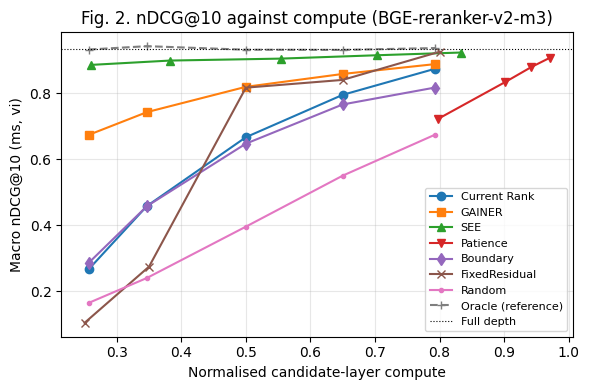

target,Malay,Vietnamese,Macro,Compute
method,,,,
First-stage order,0.8749,0.9646,0.9197,0.0000
Fixed depth,0.2407,0.5968,0.4188,0.5000
FixedResidual,0.2407,0.5968,0.4188,0.5000
Current Rank,0.4911,0.6754,0.5833,0.5000
Boundary,0.2246,0.5379,0.3813,0.5000
Patience,0.6806,0.7014,0.6910,0.8320
SEE,0.8304,0.9689,0.8996,0.5869
Random,0.2945,0.4110,0.3527,0.5000
GAINER,0.8342,0.9593,0.8967,0.5000


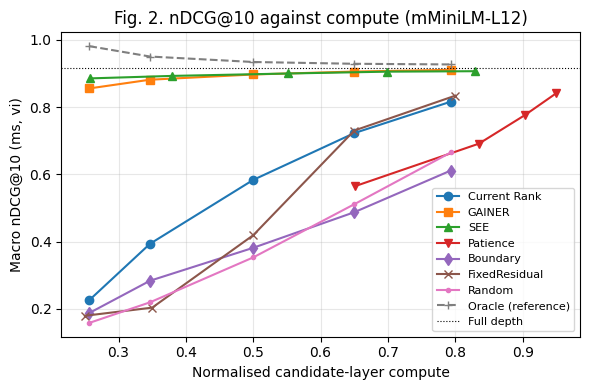

In [79]:
import matplotlib.pyplot as plt

METHODS_T6 = ["First-stage order", "Fixed depth", "FixedResidual", "Current Rank", "Boundary", "Patience", "SEE", "Random", "GAINER",
              "Oracle (reference)", "Full depth"]


def per_query_mean_over_seeds(df):
    return df.groupby(["backbone", "target", "method", "budget", "qid"], as_index=False)[["ndcg10", "r10", "mrr10", "compute"]].mean()


T = per_query_mean_over_seeds(RERANK[RERANK.kind == "test"])
T.to_csv(os.path.join(C["run_dir"], "tables", "rerank_test_mean_over_seeds.csv"), index=False)
for bbname in C["backbones"]:
    d = T[(T.backbone == bbname) & ((T.budget == C["primary_budget"]) | T.method.isin(["First-stage order", "Full depth"]))]
    t6 = d.groupby(["method", "target"]).ndcg10.mean().unstack("target").rename(columns=LANG_NAMES)
    t6["Macro"] = t6.mean(axis=1)
    t6["Compute"] = d.groupby("method").compute.mean()
    if isinstance(LAT, pd.DataFrame) and bbname == C["primary_backbone"]:
        lt = LAT[(LAT.budget == C["primary_budget"]) | (LAT.method == "Full depth")].groupby("method").ms.mean()
        t6["Latency (ms)"] = lt
    save_table(t6.reindex([m for m in METHODS_T6 if m in t6.index]).round(4), f"table6_rerank_{bbname}",
               f"TABLE VI. Re-ranking nDCG@10 at B = {C['primary_budget']:.2f}, leave-one-language-out ({bbname}, mean of {len(C['seeds'])} seeds)")
    show_table(f"table6_rerank_{bbname}")

    # Fig. 2: macro nDCG@10 against normalised compute
    fig, ax = plt.subplots(figsize=(6, 4))
    for m, mk in [("Current Rank", "o"), ("GAINER", "s"), ("SEE", "^"), ("Patience", "v"), ("Boundary", "d"), ("FixedResidual", "x"),
                  ("Random", "."), ("Oracle (reference)", "+")]:
        g = T[(T.backbone == bbname) & (T.method == m)].groupby(["budget", "target"])[["ndcg10", "compute"]].mean().groupby("budget").mean()
        ax.plot(g.compute, g.ndcg10, marker=mk, label=m, linestyle="--" if "Oracle" in m else "-")
    full = T[(T.backbone == bbname) & (T.method == "Full depth")].groupby("target").ndcg10.mean().mean()
    ax.axhline(full, color="k", lw=0.8, ls=":", label="Full depth")
    ax.set_xlabel("Normalised candidate-layer compute"); ax.set_ylabel("Macro nDCG@10 (ms, vi)")
    ax.set_title(f"Fig. 2. nDCG@10 against compute ({bbname})"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(os.path.join(C["run_dir"], "tables", f"fig2_{bbname}.png"), dpi=200); plt.show()

## From retrieved evidence to verdicts (RQ3) and end-to-end (RQ4)
Each retrieved document is reduced to its best `passage_words`-word passage (by overlap with the claim) and the top *k* = 3 passages are given to the verdict model. Evidence conditions: **claim only**, **gold evidence**, **retrieved at full depth**, and **retrieved under budget *B*** (GAINER and Current Rank, primary backbone, first seed). X-FACT claims use the evidence snippets released with X-FACT as their "gold" condition. LLMs are scored by the probability of each answer letter (deterministic, equivalent to temperature 0); option **D = "no matching evidence"** is used only for abstention.

In [80]:
VERDICT_SEED = C["seeds"][0]
PB = C["primary_backbone"]
XF = BENCH["XF"]
_passage_memo = {}


def claim_row(qid):
    base = qid.split("#")[0]
    return Q.loc[base] if base in Q.index else XF.loc[base]


def evidence_passages(qid, cond, k=None):
    """cond: 'claim_only' | 'gold' | (method, budget). Returns a list of passages."""
    k = k or C["evidence_k"]
    r = claim_row(qid)
    if cond == "claim_only":
        return []
    if cond == "gold":
        if r.collection == "SEBENARNYA-Fact":
            pool = POOLS["ms"]
            return [best_passage(pool.texts[pool.index[r.gold[0]]], r.text, r.lang)]
        words = clean_text(r.gold_evidence).split()
        return [" ".join(words[: C["passage_words"] * k])] if words else []
    method, B = cond
    docs = RANKS[(PB, VERDICT_SEED, method, B)][qid][0][:k]
    pool = POOLS[r.pool]
    out = []
    for d in docs:
        key = (qid.split("#")[0], r.pool, int(d))
        if key not in _passage_memo:
            _passage_memo[key] = best_passage(pool.texts[d], r.text, r.lang)
        out.append(_passage_memo[key])
    return out


def verdict_items(split):
    rows = [r for r in Q[(Q.split == split) & Q.label.notna() & Q.lang.isin(RET_LANGS)].itertuples()]
    if len(XF):
        rows += [r for r in XF[(XF.split == split) & XF.label.notna()].itertuples()]
    return [(r.qid, r.lang, LAB2ID[r.label]) for r in rows]


TEST_ITEMS = verdict_items("test")
RET_CONDS = [("Full depth", 1.0)] + [("GAINER", B) for B in C["budgets"] if B < 1] + [("Current Rank", C["primary_budget"])]
CONDITIONS = {"claim_only": [q for q, _, _ in TEST_ITEMS], "gold": [q for q, _, _ in TEST_ITEMS]}
for cond in RET_CONDS:
    CONDITIONS[cond] = [q for q, l, _ in TEST_ITEMS if l in RET_LANGS]
NOMATCH_IDS = [b + "#nomatch" for b in BENCH["nomatch"]]
ABST_DEV_IDS = [q for q, c in CANDS.items() if c["kind"] == "dev"]
LABEL_OF = {q: y for q, _, y in TEST_ITEMS}
LANG_OF = {q: l for q, l, _ in TEST_ITEMS}

# common evaluation subset for Table VII (all verdict models, including the LLMs)
_rng = np.random.RandomState(0)
SUBSET = []
for lang in sorted(set(LANG_OF.values())):
    qs = sorted(q for q, l in LANG_OF.items() if l == lang)
    SUBSET += sorted(_rng.choice(qs, min(len(qs), C["llm_max_per_lang"]), replace=False).tolist()) if C["run_llm"] else qs
print({l: sum(LANG_OF[q] == l for q in SUBSET) for l in sorted(set(LANG_OF.values()))}, "claims per language in the Table VII subset")

{'bn': 300, 'hi': 170, 'id': 300, 'ms': 300, 'ta': 221, 'vi': 300} claims per language in the Table VII subset


In [81]:
def macro_f1(y, p, labels):
    y, p = np.asarray(y), np.asarray(p)
    f = []
    for c in labels:
        tp = np.sum((p == c) & (y == c)); fp = np.sum((p == c) & (y != c)); fn = np.sum((p != c) & (y == c))
        f.append(2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0.0)
    return float(np.mean(f))


def macro_f1_rows(Y, P, labels):
    """Row-wise macro-F1 for matrices of gold labels Y and predictions P (shape [R, n])."""
    f = []
    for c in labels:
        tp = ((P == c) & (Y == c)).sum(1); fp = ((P == c) & (Y != c)).sum(1); fn = ((P != c) & (Y == c)).sum(1)
        den = 2 * tp + fp + fn
        f.append(np.where(den > 0, 2 * tp / np.maximum(den, 1), 0.0))
    return np.mean(f, 0)


def lang_labels(lang):
    """Labels present in the gold test set of a language (macro-F1 averages over these)."""
    return sorted(set(y for q, y in LABEL_OF.items() if LANG_OF[q] == lang))

In [82]:
def load_classifier(hf, num_labels=3):
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    tok = AutoTokenizer.from_pretrained(hf)
    return tok, AutoModelForSequenceClassification.from_pretrained(hf, num_labels=num_labels).to(DEVICE)


def clf_inputs(qids, cond, k=None):
    claims = [claim_row(q).text for q in qids]
    evs = [" | ".join(evidence_passages(q, cond, k)) for q in qids]
    return claims, evs


def train_classifier():
    from transformers import get_linear_schedule_with_warmup
    cf = C["clf"]
    tok, model = load_classifier(C["classifier_hf"])
    tr = verdict_items("train")
    dv = verdict_items("dev")
    tr_c, tr_e = clf_inputs([q for q, _, _ in tr], "gold")
    dv_c, dv_e = clf_inputs([q for q, _, _ in dv], "gold")
    ytr = np.array([y for _, _, y in tr])
    counts = np.bincount(ytr, minlength=3).astype(float)
    weights = torch.tensor(len(ytr) / (3 * np.maximum(counts, 1)), dtype=torch.float32, device=DEVICE)
    print(f"  classifier training claims: {len(tr)} (class counts {counts.astype(int).tolist()}), dev: {len(dv)}")
    opt = torch.optim.AdamW(model.parameters(), lr=cf["lr"], weight_decay=cf["weight_decay"])
    steps = cf["epochs"] * math.ceil(len(tr) / cf["batch"])
    sch = get_linear_schedule_with_warmup(opt, int(cf["warmup"] * steps), steps)
    scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE == "cuda"))
    rng = np.random.RandomState(0)
    set_seed(0)
    best, best_state = -1, None
    for ep in range(cf["epochs"]):
        model.train()
        perm = rng.permutation(len(tr))
        for s in tqdm(range(0, len(tr), cf["batch"]), desc=f"classifier epoch {ep + 1}", leave=False):
            idx = perm[s:s + cf["batch"]]
            ev = ["" if rng.random_sample() < cf["evidence_dropout"] else tr_e[i] for i in idx]   # claim-only robustness
            enc = tok([tr_c[i] for i in idx], ev, truncation="longest_first", max_length=cf["max_len"], padding=True, return_tensors="pt").to(DEVICE)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEVICE == "cuda")):
                logits = model(**enc).logits
            loss = F.cross_entropy(logits.float(), torch.as_tensor(ytr[idx], device=DEVICE), weight=weights)
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sch.step()
        pd_ = classifier_predict((tok, model), dv_c, dv_e).argmax(1)
        f1 = np.mean([macro_f1([y for (q, l, y) in dv if l == lang], pd_[[i for i, (q, l, y) in enumerate(dv) if l == lang]],
                               sorted(set(y for (q, l, y) in dv if l == lang))) for lang in sorted(set(l for _, l, _ in dv))]) if dv else 0
        print(f"  epoch {ep + 1}: dev macro-F1 (gold evidence) = {f1:.4f}")
        if f1 > best:
            best, best_state = f1, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return tok, model.eval()


@torch.no_grad()
def classifier_predict(clf, claims, evs, batch=64):
    tok, model = clf
    model.eval()
    out = []
    for s in range(0, len(claims), batch):
        enc = tok(claims[s:s + batch], evs[s:s + batch], truncation="longest_first", max_length=C["clf"]["max_len"],
                  padding=True, return_tensors="pt").to(DEVICE)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEVICE == "cuda")):
            out.append(model(**enc).logits.float().softmax(-1).cpu().numpy())
    return np.concatenate(out) if out else np.zeros((0, 3))


def run_classifier():
    clf = train_classifier()
    preds = {}
    jobs = list(CONDITIONS.items()) + [(("Full depth", 1.0, kk), CONDITIONS[("Full depth", 1.0)]) for kk in C["evidence_k_grid"] if kk != C["evidence_k"]]
    jobs += [(("nomatch", "GAINER", C["primary_budget"]), NOMATCH_IDS), (("dev", "GAINER", C["primary_budget"]), ABST_DEV_IDS)]
    for cond, qids in jobs:
        if isinstance(cond, tuple) and len(cond) == 3 and cond[0] in ("nomatch", "dev"):
            c, e = clf_inputs(qids, (cond[1], cond[2]))
        elif isinstance(cond, tuple) and len(cond) == 3:
            c, e = clf_inputs(qids, (cond[0], cond[1]), k=cond[2])
        else:
            c, e = clf_inputs(qids, cond)
        P = classifier_predict(clf, c, e)
        preds[cond] = dict(zip(qids, P))
    del clf
    free_gpu()
    return preds


FP_VERDICT = fingerprint("primary_backbone", "evidence_k", "evidence_k_grid", "passage_words", "classifier_hf", "clf",
                         fold=FP_FOLD[C["primary_backbone"]])
PRED = {"XLM-R": cached(f"verdict_xlmr_{FP_VERDICT}", run_classifier)}
_gp = np.array([int(np.argmax(v)) for v in PRED["XLM-R"]["gold"].values()])
_share = np.bincount(_gp, minlength=3) / max(1, len(_gp))
print("XLM-R predicted label shares (gold evidence, test):", dict(zip(UNIFIED, _share.round(3))))
if _share.max() > 0.95 and not C["dry_run"]:
    print("WARNING: the classifier predicts almost a single class.")

  classifier training claims: 12206 (class counts [2176, 7125, 2905]), dev: 1607


classifier epoch 1:   0%|          | 0/763 [00:00<?, ?it/s]

  epoch 1: dev macro-F1 (gold evidence) = 0.6269


classifier epoch 2:   0%|          | 0/763 [00:00<?, ?it/s]

  epoch 2: dev macro-F1 (gold evidence) = 0.7435


classifier epoch 3:   0%|          | 0/763 [00:00<?, ?it/s]

  epoch 3: dev macro-F1 (gold evidence) = 0.7695
XLM-R predicted label shares (gold evidence, test): {'Supports': np.float64(0.197), 'Refutes': np.float64(0.498), 'Context': np.float64(0.305)}


In [83]:
LLM_SYSTEM = ("You are a careful, neutral fact-checker for Southeast Asian and South Asian news. "
              "Read the claim and the evidence and choose exactly one option. Answer with a single letter.")
OPT_EVID = ("A. Supports - the evidence shows the claim is true.\n"
            "B. Refutes - the evidence shows the claim is false or misleading.\n"
            "C. Context - the evidence is about the claim but only clarifies or warns, or is not enough to decide.\n"
            "D. No match - none of the evidence is about this claim.")
OPT_NOEVID = ("A. Supports - the claim is true.\n"
              "B. Refutes - the claim is false or misleading.\n"
              "C. Context - the claim needs context, or there is not enough information to decide.")


def llm_user_message(claim, passages, with_evidence):
    if with_evidence:
        ev = "\n".join(f"[{i + 1}] {p}" for i, p in enumerate(passages)) or "(none)"
        return f"Claim: {claim}\n\nEvidence:\n{ev}\n\nWhich option is correct? Use only the evidence above.\n{OPT_EVID}\nAnswer with a single letter."
    return f"Claim: {claim}\n\nWhich option is correct? Use your own knowledge.\n{OPT_NOEVID}\nAnswer with a single letter."


_shot_memo = {}


def few_shot_examples(lang, n, with_evidence):
    if n == 0:
        return []
    if (lang, n, with_evidence) in _shot_memo:
        return _shot_memo[(lang, n, with_evidence)]
    src = Q if lang in RET_LANGS else XF
    tr = src[(src.lang == lang) & (src.split == "train") & src.label.notna()]
    rng = np.random.RandomState(0)
    msgs = []
    for lab in UNIFIED[:n]:
        g = tr[tr.label == lab]
        if not len(g):
            continue
        r = g.iloc[rng.randint(len(g))]
        ev = [" ".join(" ".join(evidence_passages(r.qid, "gold")).split()[:60])] if with_evidence else []
        msgs += [{"role": "user", "content": llm_user_message(r.text, ev, with_evidence)},
                 {"role": "assistant", "content": "ABC"[LAB2ID[lab]]}]
    _shot_memo[(lang, n, with_evidence)] = msgs
    return msgs


def load_llm(hf):
    from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
    tok = AutoTokenizer.from_pretrained(hf, padding_side="left")
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    kw = dict(torch_dtype=torch.float16 if DEVICE == "cuda" else torch.float32)
    if C["llm_4bit"] and DEVICE == "cuda":
        kw.update(quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16),
                  device_map="auto")
    model = AutoModelForCausalLM.from_pretrained(hf, **kw)
    if "device_map" not in kw:
        model = model.to(DEVICE)
    return tok, model.eval()


def letter_ids(tok, letters):
    out = []
    for L in letters:
        ids = set()
        for s in (L, " " + L):
            t = tok.encode(s, add_special_tokens=False)
            if len(t) == 1:
                ids.add(t[0])
        out.append(sorted(ids) or [tok.encode(L, add_special_tokens=False)[-1]])
    return out


@torch.no_grad()
def llm_probs(llm, qids, cond, shots):
    tok, model = llm
    with_ev = cond != "claim_only"
    letters = list("ABCD") if with_ev else list("ABC")
    lids = letter_ids(tok, letters)
    msgs = []
    for q in qids:
        r = claim_row(q)
        m = [{"role": "system", "content": LLM_SYSTEM}] + few_shot_examples(r.lang, shots, with_ev)
        m.append({"role": "user", "content": llm_user_message(r.text, evidence_passages(q, cond), with_ev)})
        msgs.append(tok.apply_chat_template(m, tokenize=False, add_generation_prompt=True))
    out = []
    dev = next(model.parameters()).device
    for s in tqdm(range(0, len(msgs), C["llm_batch"]), desc=f"LLM {cond} {shots}-shot", leave=False):
        enc = tok(msgs[s:s + C["llm_batch"]], return_tensors="pt", padding=True, add_special_tokens=False).to(dev)
        try:   # only the last position's logits are needed (full-sequence logits would not fit in memory)
            logits = model(**enc, logits_to_keep=1).logits[:, -1, :].float()
        except TypeError:
            logits = model(**enc).logits[:, -1, :].float()
        sc = torch.stack([torch.logsumexp(logits[:, ids], -1) for ids in lids], -1)
        P = sc.softmax(-1).cpu().numpy()
        if not with_ev:
            P = np.concatenate([P, np.zeros((len(P), 1))], 1)
        out.append(P)
    return dict(zip(qids, np.concatenate(out))) if out else {}


def run_llm(name, hf):
    llm = load_llm(hf)
    memo = defaultdict(dict)   # (condition, shots) -> {qid: probabilities}; prompts are deterministic, so each is scored once

    def probs(qids, cond, shots):
        todo = [q for q in qids if q not in memo[(cond, shots)]]
        if todo:
            memo[(cond, shots)].update(llm_probs(llm, todo, cond, shots))
        return {q: memo[(cond, shots)][q] for q in qids}

    res = {}
    ps = C["primary_llm_shots"]
    all_ret = CONDITIONS[("Full depth", 1.0)]   # every ms/vi test claim
    if name == C["primary_verdict_model"]:
        # end-to-end conditions for the primary verdict model, at every budget; on all test claims (H4, H5, Table VIII)
        e2e_q = all_ret if C["e2e_all_claims"] else [q for q in SUBSET if LANG_OF[q] in RET_LANGS]
        for cond in ["gold"] + RET_CONDS:
            res[("e2e", cond)] = probs(e2e_q, cond, ps)
    sub_ret = [q for q in SUBSET if LANG_OF[q] in RET_LANGS]
    for shots in C["llm_shots"]:
        res[("claim_only", shots)] = probs(SUBSET, "claim_only", shots)
        res[("gold", shots)] = probs(SUBSET, "gold", shots)
        res[(("Full depth", 1.0), shots)] = probs(sub_ret, ("Full depth", 1.0), shots)
    rng = np.random.RandomState(0)
    pb = (("GAINER", C["primary_budget"]))
    res[(pb, 0)] = probs(sub_ret, pb, 0)
    nm = [q for lang in RET_LANGS for q in sorted(rng.choice([x for x in NOMATCH_IDS if CANDS[x]["lang"] == lang],
          min(C["llm_max_per_lang"], sum(CANDS[x]["lang"] == lang for x in NOMATCH_IDS)), replace=False).tolist())]
    dv = [q for lang in RET_LANGS for q in sorted(rng.choice([x for x in ABST_DEV_IDS if CANDS[x]["lang"] == lang],
          min(C["llm_dev_per_lang"], sum(CANDS[x]["lang"] == lang for x in ABST_DEV_IDS)), replace=False).tolist())]
    res[(("nomatch",) + pb, 0)] = llm_probs(llm, nm, pb, 0)
    res[(("dev",) + pb, 0)] = llm_probs(llm, dv, pb, 0)
    del llm
    free_gpu()
    return res


if C["run_llm"]:
    for name, hf in C["llms"].items():
        PRED[name] = cached(f"verdict_llm_{name}_{fingerprint('llm_4bit', 'llm_shots', 'llm_batch', 'llm_max_per_lang', 'llm_dev_per_lang', 'run_llm', 'primary_verdict_model', 'primary_llm_shots', 'e2e_all_claims', hf=hf, v=FP_VERDICT)}",
                            lambda: run_llm(name, hf))

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

LLM gold 3-shot:   0%|          | 0/547 [00:00<?, ?it/s]

LLM ('Full depth', 1.0) 3-shot:   0%|          | 0/547 [00:00<?, ?it/s]

LLM ('GAINER', 0.25) 3-shot:   0%|          | 0/547 [00:00<?, ?it/s]

LLM ('GAINER', 0.35) 3-shot:   0%|          | 0/547 [00:00<?, ?it/s]

...

LLM claim_only 3-shot:   0%|          | 0/398 [00:00<?, ?it/s]

LLM gold 3-shot:   0%|          | 0/248 [00:00<?, ?it/s]

LLM ('GAINER', 0.5) 0-shot:   0%|          | 0/150 [00:00<?, ?it/s]

LLM ('GAINER', 0.5) 0-shot:   0%|          | 0/100 [00:00<?, ?it/s]

LLM ('GAINER', 0.5) 0-shot:   0%|          | 0/75 [00:00<?, ?it/s]

In [84]:
def f1_for(pred, qids, lang):
    qs = [q for q in qids if LANG_OF.get(q) == lang and q in pred]
    if not qs:
        return np.nan
    return macro_f1([LABEL_OF[q] for q in qs], [int(np.argmax(pred[q][:3])) for q in qs], lang_labels(lang))


def model_variants():
    out = [("XLM-RoBERTa (fine-tuned)", lambda cond: PRED["XLM-R"].get(cond, {}))]
    for name in (C["llms"] if C["run_llm"] else {}):
        for shots in C["llm_shots"]:
            out.append((f"{name}, " + {0: "zero-shot", 3: "three-shot"}.get(shots, f"{shots}-shot"),
                        lambda cond, name=name, shots=shots: PRED[name].get((cond, shots), {})))
    return out


rows, rows_lang = [], []
for label, get in model_variants():
    r = {"Verdict model": label}
    for col, cond in [("Claim only", "claim_only"), ("Gold evidence", "gold"), ("Retrieved (full depth)", ("Full depth", 1.0))]:
        r[col] = np.nanmean([f1_for(get(cond), SUBSET, l) for l in RET_LANGS])
        for l in sorted(set(LANG_OF.values())):
            rows_lang.append({"Verdict model": label, "condition": col, "language": LANG_NAMES.get(l, l), "macro_f1": f1_for(get(cond), SUBSET, l)})
    r["Gap (gold − retrieved)"] = r["Gold evidence"] - r["Retrieved (full depth)"]
    rows.append(r)
save_table((pd.DataFrame(rows).set_index("Verdict model") * 100).round(2), "table7_verdict",
           f"TABLE VII. Verdict macro-F1 (×100, unified labels, macro over ms and vi) by evidence condition, k = {C['evidence_k']}, on the common evaluation subset")
t7b = pd.DataFrame(rows_lang).pivot_table(index=["Verdict model", "condition"], columns="language", values="macro_f1") * 100
save_table(t7b.round(2), "table7b_verdict_by_language", "TABLE VII(b). Verdict macro-F1 (×100) by language (X-FACT: provided evidence snippets as 'gold')")
kk = {f"k = {k}": np.nanmean([f1_for(PRED["XLM-R"].get(("Full depth", 1.0) if k == C["evidence_k"] else ("Full depth", 1.0, k), {}),
                                     CONDITIONS[("Full depth", 1.0)], l) for l in RET_LANGS]) * 100 for k in C["evidence_k_grid"]}
save_table(pd.DataFrame([kk], index=["XLM-R, retrieved (full depth)"]).round(2), "table7c_evidence_k", "Exploratory: effect of k (XLM-R, full test sets)")
show_table("table7_verdict")

,Claim only,Gold evidence,Retrieved (full depth),Gap (gold − retrieved)
Verdict model,,,,
XLM-RoBERTa (fine-tuned),47.19,73.09,60.70,12.39
"Qwen2.5-7B-Instruct, zero-shot",32.03,40.73,44.31,-3.58
"Qwen2.5-7B-Instruct, three-shot",46.13,43.72,42.59,1.13


In [85]:
if C["primary_verdict_model"] == "XLM-R":
    PRIMARY_PRED = lambda cond: PRED["XLM-R"].get(cond, {})
    E2E_QIDS = CONDITIONS[("Full depth", 1.0)]
else:
    assert C["run_llm"] and C["primary_verdict_model"] in C["llms"], "the primary verdict model must be one of `llms`"
    PRIMARY_PRED = lambda cond: PRED[C["primary_verdict_model"]].get(("e2e", cond), {})
    E2E_QIDS = CONDITIONS[("Full depth", 1.0)] if C["e2e_all_claims"] else [q for q in SUBSET if LANG_OF[q] in RET_LANGS]


def f1_data(cond_a, cond_b, qids):
    """Per language: gold labels and the two systems' predictions on the same claims."""
    pa, pb = PRIMARY_PRED(cond_a), PRIMARY_PRED(cond_b)
    data = {}
    for l in RET_LANGS:
        qs = [q for q in qids if LANG_OF.get(q) == l and q in pa and q in pb]
        if qs:
            data[l] = (np.array([LABEL_OF[q] for q in qs]), np.array([int(np.argmax(pa[q][:3])) for q in qs]),
                       np.array([int(np.argmax(pb[q][:3])) for q in qs]), lang_labels(l))
    return data

In [86]:
def signflip_test(diffs, n_perm, seed=0, chunk=2000):
    """Two-sided paired sign-flip randomisation test, stratified by language; statistic = macro mean difference."""
    langs = [l for l in diffs if len(diffs[l])]
    obs = np.mean([np.mean(diffs[l]) for l in langs])
    rng = np.random.RandomState(seed)
    hits = 0
    for s in range(0, n_perm, chunk):
        m = min(chunk, n_perm - s)
        stat = np.mean([(np.where(rng.random_sample((m, len(diffs[l]))) < 0.5, -1.0, 1.0) * diffs[l]).mean(1) for l in langs], 0)
        hits += int((np.abs(stat) >= abs(obs) - 1e-12).sum())
    return float(obs), (hits + 1) / (n_perm + 1)


def bootstrap_ci(diffs, n_boot, seed=1):
    rng = np.random.RandomState(seed)
    langs = [l for l in diffs if len(diffs[l])]
    reps = np.mean([np.asarray(diffs[l])[rng.randint(0, len(diffs[l]), (n_boot, len(diffs[l])))].mean(1) for l in langs], 0)
    return float(np.percentile(reps, 2.5)), float(np.percentile(reps, 97.5)), reps


def swap_test_f1(data, n_perm, seed=0, chunk=500):
    """Two-sided paired randomisation test: swap the two systems' predictions per claim; statistic = macro over languages of the macro-F1 difference."""
    obs = np.mean([macro_f1(y, a, lab) - macro_f1(y, b, lab) for y, a, b, lab in data.values()])
    rng = np.random.RandomState(seed)
    hits = 0
    for s in range(0, n_perm, chunk):
        m = min(chunk, n_perm - s)
        st = []
        for y, a, b, lab in data.values():
            sw = rng.random_sample((m, len(y))) < 0.5
            A, B = np.where(sw, b, a), np.where(sw, a, b)
            Y = np.broadcast_to(y, A.shape)
            st.append(macro_f1_rows(Y, A, lab) - macro_f1_rows(Y, B, lab))
        hits += int((np.abs(np.mean(st, 0)) >= abs(obs) - 1e-12).sum())
    return float(obs), (hits + 1) / (n_perm + 1)


def bootstrap_f1_diff(data, n_boot, seed=1, chunk=500):
    rng = np.random.RandomState(seed)
    reps = []
    for s in range(0, n_boot, chunk):
        m = min(chunk, n_boot - s)
        st = []
        for y, a, b, lab in data.values():
            idx = rng.randint(0, len(y), (m, len(y)))
            st.append(macro_f1_rows(y[idx], a[idx], lab) - macro_f1_rows(y[idx], b[idx], lab))
        reps.append(np.mean(st, 0))
    reps = np.concatenate(reps)
    return float(np.percentile(reps, 2.5)), float(np.percentile(reps, 97.5)), reps


def holm(pvals):
    keys = [k for k in pvals if pvals[k] is not None and not np.isnan(pvals[k])]
    order = sorted(keys, key=lambda k: pvals[k])
    adj, running = {}, 0.0
    for i, k in enumerate(order):
        running = max(running, min(1.0, (len(order) - i) * pvals[k]))
        adj[k] = running
    return adj


def paired_diffs(df, key_a, key_b, value="ndcg10", by="lang", on="qid"):
    out = {}
    for l, g in df.groupby(by):
        a = g[g.sys == key_a].set_index(on)[value]
        b = g[g.sys == key_b].set_index(on)[value]
        common = a.index.intersection(b.index)
        out[l] = (a[common] - b[common]).values.astype(float)
    return out

In [87]:
lat_ms = {}
if isinstance(LAT, pd.DataFrame) and len(LAT):
    lat_ms = LAT[LAT.method.isin(["GAINER", "Full depth"])].groupby(["method", "budget"]).ms.mean().to_dict()
rows = []
Tp = T[T.backbone == PB]
for B in C["budgets"]:
    cond = ("Full depth", 1.0) if B >= 1 else ("GAINER", B)
    m = "Full depth" if B >= 1 else "GAINER"
    nd = Tp[(Tp.method == m) & (np.isclose(Tp.budget, B))].groupby("target").ndcg10.mean().mean()
    data = f1_data(cond, ("Full depth", 1.0), E2E_QIDS)
    if not data:   # e.g. an LLM primary verdict model that was only run at the primary budget
        rows.append({"Budget B": B, "Re-ranking nDCG@10": round(nd, 4)})
        continue
    f1 = np.mean([macro_f1(y, a, lab) for y, a, b, lab in data.values()])
    if B < 1:
        lo, hi, _ = bootstrap_f1_diff(data, C["n_bootstrap"])
        diff = f"{(f1 - np.mean([macro_f1(y, b, lab) for y, a, b, lab in data.values()])) * 100:+.2f} [{lo * 100:+.2f}, {hi * 100:+.2f}]"
    else:
        diff = "0"
    lat = lat_ms.get((m, B))
    full_lat = lat_ms.get(("Full depth", 1.0))
    rows.append({"Budget B": B, "Re-ranking nDCG@10": round(nd, 4), "Verdict macro-F1 (×100)": round(f1 * 100, 2),
                 "Difference from full depth (95% CI)": diff, "Latency per claim (ms)": None if lat is None else round(lat, 1),
                 "Speed-up": None if (lat is None or full_lat is None) else f"{full_lat / lat:.2f}×"})
data = f1_data(("GAINER", C["primary_budget"]), ("Current Rank", C["primary_budget"]), E2E_QIDS)
if data:
    lo, hi, _ = bootstrap_f1_diff(data, C["n_bootstrap"])
    save_table(pd.DataFrame([{"GAINER macro-F1 (×100)": np.mean([macro_f1(y, a, lab) for y, a, b, lab in data.values()]) * 100,
                              "Current Rank macro-F1 (×100)": np.mean([macro_f1(y, b, lab) for y, a, b, lab in data.values()]) * 100,
                              "95% CI of difference (points)": f"[{lo * 100:+.2f}, {hi * 100:+.2f}]"}], index=[f"B = {C['primary_budget']}"]).round(2),
               "table8b_verdict_gainer_vs_currentrank", "Supplementary: verdict macro-F1 with evidence re-ranked by GAINER vs. Current Rank")
save_table(pd.DataFrame(rows).set_index("Budget B"), "table8_end_to_end",
           f"TABLE VIII. End-to-end results with {C['primary_verdict_model']} by re-ranking budget (GAINER, {PB}; macro over ms and vi; latency = re-ranking only, tokenization excluded)")
show_table("table8_end_to_end")

,Re-ranking nDCG@10,Verdict macro-F1 (×100),Difference from full depth (95% CI),Latency per claim (ms),Speed-up
Budget B,,,,,
0.25,0.6741,43.63,"-0.92 [-2.66, +0.83]",71.0,3.50×
0.35,0.7430,42.86,"-1.69 [-3.28, -0.07]",91.6,2.71×
0.50,0.8198,42.42,"-2.13 [-3.56, -0.73]",128.4,1.93×
0.65,0.8589,42.90,"-1.65 [-2.92, -0.40]",166.1,1.49×
0.80,0.8888,43.43,"-1.12 [-2.30, +0.05]",200.6,1.24×
1.00,0.9333,44.55,0,248.2,1.00×


## Abstention on no-match claims
For no-match claims the gold evidence was removed from the pool, so the right behaviour is to abstain. Thresholds are set per language on **dev** claims only (no labels used) so that `abstain_target_coverage` of ordinary claims are answered. Abstention precision = share of abstentions that are no-match claims; recall = share of no-match claims that were abstained on; selective accuracy = verdict accuracy on the most confident 80% of ordinary test claims.

In [88]:
def abstention_table():
    rows, per_lang = [], []
    B = C["primary_budget"]
    rk = RANKS[(PB, VERDICT_SEED, "GAINER", B)]
    mechs = [("Re-ranker score threshold", {q: v[1] for q, v in rk.items()}, PRED["XLM-R"][("GAINER", B)],
              ABST_DEV_IDS, NOMATCH_IDS)]
    if C["run_llm"]:
        for name in C["llms"]:
            P = PRED[name]
            dv, nm, normal = P[(("dev", "GAINER", B), 0)], P[(("nomatch", "GAINER", B), 0)], P[(("GAINER", B), 0)]
            conf = {q: 1.0 - float(v[3]) for d in (dv, nm, normal) for q, v in d.items()}
            mechs.append((f'LLM "no matching evidence" ({name})', conf, normal, list(dv), list(nm)))
    for mname, conf, preds, dev_ids, nm_ids in mechs:
        agg = defaultdict(list)
        for l in RET_LANGS:
            dev = [q for q in dev_ids if CANDS[q]["lang"] == l]
            nm = [q for q in nm_ids if CANDS[q]["lang"] == l]
            normal = [q for q in preds if LANG_OF.get(q) == l]
            if not dev or not nm or not normal:
                continue
            tau = np.quantile([conf[q] for q in dev], 1 - C["abstain_target_coverage"])
            abst_nm = np.array([conf[q] < tau for q in nm])
            abst_norm = np.array([conf[q] < tau for q in normal])
            n_abst = abst_nm.sum() + abst_norm.sum()
            prec = abst_nm.sum() / n_abst if n_abst else np.nan
            rec = abst_nm.mean()
            cf = np.array([conf[q] for q in normal])
            keep = np.argsort(-cf, kind="stable")[: int(math.ceil(C["selective_coverage"] * len(normal)))]
            acc = np.mean([int(np.argmax(preds[normal[i]][:3])) == LABEL_OF[normal[i]] for i in keep])
            full_acc = np.mean([int(np.argmax(preds[q][:3])) == LABEL_OF[q] for q in normal])
            per_lang.append(dict(mechanism=mname, language=LANG_NAMES[l], tau=tau, abstention_precision=prec, abstention_recall=rec,
                                 selective_accuracy_80=acc, accuracy_full_coverage=full_acc, n_normal=len(normal), n_nomatch=len(nm), n_dev=len(dev)))
            for k, v in [("p", prec), ("r", rec), ("a", acc)]:
                agg[k].append(v)
        if agg:
            rows.append({"Mechanism": mname, "Abstention precision": np.nanmean(agg["p"]), "Abstention recall": np.nanmean(agg["r"]),
                         "Selective accuracy at 80% coverage": np.nanmean(agg["a"])})
    save_table(pd.DataFrame(per_lang).set_index("mechanism").round(4), "table9b_abstention_by_language", "Abstention by language")
    return save_table(pd.DataFrame(rows).set_index("Mechanism").round(4), "table9_abstention",
                      f"TABLE IX. Abstention on the no-match subset (macro over ms and vi; thresholds from dev at {C['abstain_target_coverage']:.0%} coverage)")


abstention_table()
show_table("table9_abstention")

,Abstention precision,Abstention recall,Selective accuracy at 80% coverage
Mechanism,,,
Re-ranker score threshold,0.7319,0.3975,0.7922
"LLM ""no matching evidence"" (Qwen2.5-7B-Instruct)",0.7235,0.3400,0.4729


## Pre-registered hypotheses
Holm correction is applied within each family of hypotheses: F1 (H1–H3 and H6) and F2 (H4–H5) in the pre-registration file, called families I and II in the paper. H5 is decided by its confidence interval as registered, and its one-sided bootstrap p-value enters the Holm correction of F2.

In [89]:
def evaluate_hypotheses():
    res = {}
    R = RET_ROWS[(RET_ROWS.split == "test") & ~RET_ROWS.paraphrase & RET_ROWS.lang.isin(RET_LANGS)].rename(columns={"retriever": "sys"})
    dev = RET_ROWS[(RET_ROWS.split == "dev") & RET_ROWS.lang.isin(RET_LANGS)]
    singles = ["BM25"] + list(C["dense_models"])
    dev_macro = dev[dev.retriever.isin(singles)].groupby(["retriever", "lang"]).ndcg10.mean().groupby("retriever").mean()
    best_single = dev_macro.idxmax()
    d = paired_diffs(R, HYBRID, best_single)
    eff, p = signflip_test(d, C["n_permutations"]); lo, hi, _ = bootstrap_ci(d, C["n_bootstrap"])
    res["H1"] = dict(comparison=f"{HYBRID} − {best_single} (best single on dev)", metric="nDCG@10", effect=eff, ci=(lo, hi), p=p, direction=+1)

    ft = C["finetune"]["model"] + " (fine-tuned)"
    if ft in RUNS:
        if BENCH["paraphrases"]:
            sub = RET_ROWS[RET_ROWS.paraphrase].rename(columns={"retriever": "sys"}); subset = "paraphrased"
        else:
            sub = R[R.low_overlap]; subset = "low-overlap (no paraphrases supplied)"
        d = paired_diffs(sub, ft, C["finetune"]["model"])
        eff, p = signflip_test(d, C["n_permutations"]); lo, hi, _ = bootstrap_ci(d, C["n_bootstrap"])
        res["H2"] = dict(comparison=f"{ft} − zero-shot, {subset} subset", metric="nDCG@10", effect=eff, ci=(lo, hi), p=p, direction=+1)
    else:
        res["H2"] = dict(comparison="not run (finetune_dense=False)", metric="nDCG@10", effect=np.nan, ci=(np.nan, np.nan), p=np.nan, direction=+1)

    Tb = T[(T.backbone == PB) & np.isclose(T.budget, C["primary_budget"])].rename(columns={"method": "sys", "target": "lang"})
    d = paired_diffs(Tb, "GAINER", "Current Rank")
    eff, p = signflip_test(d, C["n_permutations"]); lo, hi, _ = bootstrap_ci(d, C["n_bootstrap"])
    res["H3"] = dict(comparison=f"GAINER − Current Rank at B = {C['primary_budget']}, LOLO, {PB}", metric="nDCG@10", effect=eff, ci=(lo, hi), p=p, direction=+1)

    d = paired_diffs(Tb, "GAINER", "SEE")
    eff, p = signflip_test(d, C["n_permutations"]); lo, hi, _ = bootstrap_ci(d, C["n_bootstrap"])
    res["H6"] = dict(comparison=f"GAINER − SEE at B = {C['primary_budget']}, LOLO, {PB}", metric="nDCG@10", effect=eff, ci=(lo, hi), p=p, direction=+1)

    data = f1_data(("Full depth", 1.0), "gold", E2E_QIDS)
    eff, p = swap_test_f1(data, C["n_permutations_f1"]); lo, hi, _ = bootstrap_f1_diff(data, C["n_bootstrap"])
    res["H4"] = dict(comparison=f"retrieved (full depth) − gold evidence, {C['primary_verdict_model']}", metric="macro-F1", effect=eff, ci=(lo, hi), p=p, direction=-1)

    data = f1_data(("GAINER", C["primary_budget"]), ("Full depth", 1.0), E2E_QIDS)
    obs = np.mean([macro_f1(y, a, lab) - macro_f1(y, b, lab) for y, a, b, lab in data.values()])
    lo, hi, reps = bootstrap_f1_diff(data, C["n_bootstrap"])
    delta = C["noninferiority_delta"] / 100
    res["H5"] = dict(comparison=f"GAINER at B = {C['primary_budget']} − full depth (margin −{C['noninferiority_delta']} point)", metric="macro-F1",
                     effect=obs, ci=(lo, hi), p=float((np.sum(reps <= -delta) + 1) / (len(reps) + 1)), direction=0)

    for fam in PREREG["families"].values():
        adj = holm({h: res[h]["p"] for h in fam})
        for h in fam:
            res[h]["p_holm"] = adj.get(h, np.nan)
    rows = []
    for h, r in res.items():
        if h == "H5":
            ok = r["ci"][0] > -delta
        else:
            ok = bool(r["p_holm"] < C["alpha"] and np.sign(r["effect"]) == r["direction"])
        scale = 100 if r["metric"] == "macro-F1" else 1
        rows.append({"ID": h, "Hypothesis": PREREG["hypotheses"][h], "Comparison": r["comparison"],
                     "Effect": round(r["effect"] * scale, 4), "95% CI": f"[{r['ci'][0] * scale:+.4f}, {r['ci'][1] * scale:+.4f}]",
                     "p": r["p"], "Holm p": r.get("p_holm"), "Supported": "yes" if ok else "no"})
    return save_table(pd.DataFrame(rows).set_index("ID"), "table4_hypotheses_results",
                      "Pre-registered hypotheses: results (macro-F1 effects in points, nDCG@10 effects as fractions)")


HYP = evaluate_hypotheses()
show_table("table4_hypotheses_results")

,Hypothesis,Comparison,Effect,95% CI,p,Holm p,Supported
ID,,,,,,,
H1,Hybrid retrieval (BM25 + BGE-M3) beats the bes...,BM25 + BGE-M3 (hybrid) − BM25 (best single on ...,0.0054,"[+0.0005, +0.0104]",0.032970,0.065939,no
H2,Fine-tuned BGE-M3 beats zero-shot BGE-M3 in nD...,"BGE-M3 (fine-tuned) − zero-shot, low-overlap (...",0.0115,"[-0.0093, +0.0317]",0.281077,0.281077,no
H3,Multilingual GAINER beats the score-based casc...,"GAINER − Current Rank at B = 0.5, LOLO, BGE-re...",0.1529,"[+0.1373, +0.1687]",0.000010,0.000040,yes
H6,Multilingual GAINER beats SEE (exit before blo...,"GAINER − SEE at B = 0.5, LOLO, BGE-reranker-v2-m3",-0.0856,"[-0.0979, -0.0733]",0.000010,0.000040,no
H4,Verdict macro-F1 of the primary verdict model ...,"retrieved (full depth) − gold evidence, Qwen2....",-0.0240,"[-2.0941, +2.0084]",0.981302,1.000000,no
H5,End-to-end verdict macro-F1 with GAINER at B =...,GAINER at B = 0.5 − full depth (margin −1.0 po...,-2.1302,"[-3.5577, -0.7272]",0.942006,1.000000,no


In [90]:
def export_all():
    tdir = os.path.join(C["run_dir"], "tables")
    caps = json.load(open(os.path.join(tdir, "captions.json")))
    md = [f"# Results — {PREREG['title']}", "", f"Pre-registration SHA-256: `{PREREG_HASH}`", f"Run: {'DRY RUN (not for reporting)' if C['dry_run'] else 'full registered run'}",
          f"Generated: {datetime.datetime.now(datetime.timezone.utc).isoformat()}", ""]
    for name, cap in caps.items():
        df = pd.read_csv(os.path.join(tdir, name + ".csv"), index_col=0)
        md += [f"## {cap or name}", ""]
        try:
            md.append(df.to_markdown())
        except Exception:
            md.append("```\n" + df.to_string() + "\n```")
        md.append("")
    open(os.path.join(C["run_dir"], "tables.md"), "w", encoding="utf-8").write("\n".join(md))
    import transformers, sentence_transformers
    env = dict(python=os.sys.version, torch=torch.__version__, transformers=transformers.__version__,
               sentence_transformers=sentence_transformers.__version__, device=torch.cuda.get_device_name(0) if DEVICE == "cuda" else "cpu",
               utc=datetime.datetime.now(datetime.timezone.utc).isoformat(), prereg_sha256=PREREG_HASH, config=C)
    json.dump(env, open(os.path.join(C["run_dir"], "environment.json"), "w"), indent=1, default=str)
    zpath = os.path.join(C["out_dir"], f"seafact_results_{'dry' if C['dry_run'] else 'full'}.zip")
    with zipfile.ZipFile(zpath, "w", zipfile.ZIP_DEFLATED) as z:
        for root, _, files in os.walk(C["run_dir"]):
            if os.sep + "cache" in root:
                continue
            for f in files:
                z.write(os.path.join(root, f), os.path.relpath(os.path.join(root, f), C["out_dir"]))
    print("Wrote", os.path.join(C["run_dir"], "tables.md"), "and", zpath)
    return zpath


ZIP = export_all()
try:
    from google.colab import files as colab_files
    colab_files.download(ZIP)
except Exception:
    pass

Wrote /content/drive/MyDrive/seafact_runs/full_run/tables.md and /content/drive/MyDrive/seafact_runs/seafact_results_full.zip


## Exploratory diagnosis (not part of the registered analysis)
This section does not change any registered table. It reads the cached stages and writes to `run_dir/exploratory/`, and every comparison uses the development claims of each target language, never the test claims.

**Question.** Does GAINER fail on BGE-reranker-v2-m3 because its learned components do not transfer across languages, or because the allocation does not work on this backbone? Each variant at B = 0.50 changes one element of the registered configuration:
1. `registered`: leave-one-language-out (LOLO), ranker input = [CLS; 13 features], DAgger.
2. `features_only`: LOLO, ranker input = the 13 features only, without the [CLS] vector.
3. `cls_standardised`: LOLO, [CLS] standardised per dimension on source-language training rows.
4. `no_dagger`: LOLO, on-policy states without the DAgger round.
5. `in_language` (reference): trained on the target language's own training claims.
6. `all_languages` (reference): trained on all three languages.

**Decision rule, fixed before the output was inspected.** A second pre-registered run is made only if the best LOLO variant (1–4) by macro development nDCG@10 at B = 0.50, averaged over five seeds, beats SEE on the same claims.

In [121]:
EXPL_DIR = os.path.join(C["run_dir"], "exploratory")
os.makedirs(EXPL_DIR, exist_ok=True)
EXPL_VARIANTS = {
    "registered":       dict(sources="lolo", cls="raw", training="dagger"),
    "features_only":    dict(sources="lolo", cls="none", training="dagger"),
    "cls_standardised": dict(sources="lolo", cls="std", training="dagger"),
    "no_dagger":        dict(sources="lolo", cls="raw", training="onpolicy"),
    "in_language":      dict(sources="target", cls="raw", training="dagger"),
    "all_languages":    dict(sources="all", cls="raw", training="dagger"),
}


def expl_split(rd, langs, seed):
    """As split_sources_seafact, for an explicit list of source languages."""
    rng = np.random.default_rng(seed)
    tr, va = [], []
    for name in rd.datasets:
        lang, kind = name.split("_", 1)
        if kind != "source" or lang not in langs:
            continue
        q = rd.queries_of([name]).cpu().numpy()
        q = q[rng.permutation(len(q))][:BALANCE_CAP]
        n_val = max(1, int(round(SOURCE_VAL_FRACTION * len(q))))
        va.extend(q[:n_val]); tr.extend(q[n_val:])
    Tt = lambda x: torch.tensor(sorted(x), device=DEVICE, dtype=torch.long)
    return Tt(tr), Tt(va)


def cls_variant(rd, mode, train_q):
    """RunData whose controller input uses raw, no, or standardised [CLS] vectors (exit heads always use raw [CLS])."""
    if mode == "raw":
        return rd
    if mode == "none":
        return RunData(**{**rd.__dict__, "cls": [torch.zeros((rd.Q, rd.N, 0), dtype=torch.float16, device=DEVICE) for _ in rd.cls]})
    new = []
    for X in rd.cls:
        tq, ti = _flat_rows(rd, train_q)
        rows = X[tq, ti].float()
        mu, sd = rows.mean(0), rows.std(0).clamp(min=1e-4)
        Z = torch.empty_like(X)
        for a in range(0, rd.Q, 256):
            Z[a:a + 256] = ((X[a:a + 256].float() - mu) / sd).clamp(-50, 50).to(X.dtype)
        new.append(Z)
    return RunData(**{**rd.__dict__, "cls": new})


def run_expl(bbname, target, seed, vname):
    rd = RD[bbname]
    v = EXPL_VARIANTS[vname]
    langs = {"lolo": [l for l in ["ms", "vi", "en"] if l != target], "target": [target], "all": ["ms", "vi", "en"]}[v["sources"]]
    seed_everything(seed)
    train_q, val_q = expl_split(rd, langs, seed)
    heads = {ci: fit_exit_head(rd, ci, train_q, val_q, seed * 1000 + ci) for ci in range(rd.C - 1)}
    S = predict_exit_scores(rd, heads)
    rdx = cls_variant(rd, v["cls"], train_q)
    ctrl = train_gainer(rdx, S, train_q, val_q, dict(MAIN, training=v["training"]), seed)
    dev_q = rd.queries_of([f"{target}_dev"])
    r = survival_for_budget(PRIMARY_BUDGET, rd.layers)
    out = dict(backbone=bbname, target=target, seed=seed, variant=vname)
    sc, d = rollout(rdx, S[dev_q], dev_q, r, "gainer", controller=ctrl)
    out["GAINER"] = float(evaluate_scores(rd, dev_q, sc).mean())
    if vname == "registered":   # references on the same dev claims
        src_q = torch.cat([train_q, val_q])
        sc, _ = rollout(rd, S[dev_q], dev_q, r, "current_rank")
        out["Current Rank"] = float(evaluate_scores(rd, dev_q, sc).mean())
        out["Full depth"] = float(evaluate_scores(rd, dev_q, S[dev_q][..., -1]).mean())
        out["First-stage order"] = float(evaluate_scores(rd, dev_q, -torch.arange(rd.N, device=DEVICE, dtype=torch.float32).expand(len(dev_q), rd.N)).mean())
        delta = calibrate(lambda dd: float(see_exit(rd, src_q, dd)[1].mean()), PRIMARY_BUDGET, 0.0, 1.0, increasing=True)
        if delta is not None:
            sc, cost = see_exit(rd, dev_q, delta)
            out["SEE"] = float(evaluate_scores(rd, dev_q, sc).mean()); out["SEE compute"] = float(cost.mean())
    del rdx
    free_gpu()
    return out


expl_rows = []
for bbname in C["backbones"]:
    vnames = list(EXPL_VARIANTS) if bbname == C["primary_backbone"] else ["registered", "features_only", "cls_standardised"]
    for target in RET_LANGS:
        for seed in C["seeds"]:
            for vname in vnames:
                key = f"expl_{bbname}_{target}_{seed}_{vname}_{FP_FOLD[bbname]}"
                expl_rows.append(cached(key, lambda: run_expl(bbname, target, seed, vname)))
EXPL = pd.DataFrame(expl_rows)
EXPL.to_csv(os.path.join(EXPL_DIR, "exploratory_per_seed.csv"), index=False)

# summary: dev nDCG@10 at B = 0.50, mean (and SD) over seeds, per target language and macro
g = EXPL.groupby(["backbone", "variant", "target"]).GAINER.agg(["mean", "std"]).unstack("target")
summ = pd.DataFrame({f"{LANG_NAMES[t]} (mean)": g[("mean", t)] for t in RET_LANGS})
for t in RET_LANGS:
    summ[f"{LANG_NAMES[t]} (SD over seeds)"] = g[("std", t)]
summ["Macro"] = summ[[f"{LANG_NAMES[t]} (mean)" for t in RET_LANGS]].mean(axis=1)
refs = EXPL[EXPL.variant == "registered"].groupby(["backbone", "target"])[["First-stage order", "Current Rank", "SEE", "Full depth"]].mean()
ref_rows = []
for (bb, m) in [(bb, m) for bb in C["backbones"] for m in ["First-stage order", "Current Rank", "SEE", "Full depth"]]:
    vals = {f"{LANG_NAMES[t]} (mean)": refs.loc[(bb, t), m] for t in RET_LANGS if (bb, t) in refs.index}
    ref_rows.append(dict(backbone=bb, variant=f"[reference] {m}", **vals, Macro=np.mean(list(vals.values()))))
summ = pd.concat([summ.reset_index(), pd.DataFrame(ref_rows)], ignore_index=True).set_index(["backbone", "variant"]).round(4)
summ.to_csv(os.path.join(EXPL_DIR, "exploratory_summary.csv"))
display(summ)

# decision rule (fixed above)
pb = C["primary_backbone"]
cand = summ.loc[pb].loc[["registered", "features_only", "cls_standardised", "no_dagger"], "Macro"]
best = cand.idxmax()
see_macro = summ.loc[(pb, "[reference] SEE"), "Macro"]
print(f"Best LOLO variant on dev ({pb}): {best} (macro {cand[best]:.4f}) vs SEE {see_macro:.4f} ->",
      "candidate for a second pre-registered run" if cand[best] > see_macro else "no LOLO variant beats SEE: no second run")

# verdict models on dev claims (same claims for both; Qwen zero-shot is the only LLM condition scored on dev)
dev_lab = {q: LAB2ID[Q.loc[q.split("#")[0], "label"]] for q in ABST_DEV_IDS if pd.notna(Q.loc[q.split("#")[0], "label"])}
vrows = []
if C["run_llm"]:
    for name in C["llms"]:
        P_llm = PRED[name].get((("dev", "GAINER", C["primary_budget"]), 0), {})
        P_x = PRED["XLM-R"].get(("dev", "GAINER", C["primary_budget"]), {})
        for l in RET_LANGS:
            qs = [q for q in P_llm if q in P_x and q in dev_lab and CANDS[q]["lang"] == l]
            if not qs:
                continue
            y = [dev_lab[q] for q in qs]
            labs = sorted(set(y))
            vrows.append({"language": LANG_NAMES[l], "claims": len(qs),
                          "XLM-R macro-F1": macro_f1(y, [int(np.argmax(P_x[q][:3])) for q in qs], labs) * 100,
                          f"{name} zero-shot macro-F1": macro_f1(y, [int(np.argmax(P_llm[q][:3])) for q in qs], labs) * 100})
if vrows:
    vdev = pd.DataFrame(vrows).set_index("language").round(2)
    vdev.to_csv(os.path.join(EXPL_DIR, "verdict_models_dev.csv"))
    display(vdev)

Malay (mean)  \
backbone           variant                                       
BGE-reranker-v2-m3 all_languages                        0.8187   
                   cls_standardised                     0.7105   
                   features_only                        0.7499   
                   in_language                          0.8132   
                   no_dagger                            0.7389   
                   registered                           0.7229   
mMiniLM-L12        cls_standardised                     0.7592   
                   features_only                        0.7803   
                   registered                           0.7890   
BGE-reranker-v2-m3 [reference] First-stage order        0.8294   
                   [reference] Current Rank             0.5396   
                   [reference] SEE                      0.7542   
                   [reference] Full depth               0.8173   
mMiniLM-L12        [reference] First-stage order        0.8294   
                   [reference] Current Rank             0.3189   
                   [reference] SEE                      0.7419   
                   [reference] Full depth               0.7880   

                                                  Vietnamese (mean)  \
backbone           variant                                            
BGE-reranker-v2-m3 all_languages                             0.9772   
                   cls_standardised                          0.9164   
                   features_only                             0.9466   
                   in_language                               0.9796   
                   no_dagger                                 0.9319   
                   registered                                0.9166   
mMiniLM-L12        cls_standardised                          0.9265   
                   features_only                             0.9546   
                   registered                                0.9547   
BGE-reranker-v2-m3 [reference] First-stage order             0.9666   
                   [reference] Current Rank                  0.7189   
                   [reference] SEE                           0.9750   
                   [reference] Full depth                    0.9778   
mMiniLM-L12        [reference] First-stage order             0.9666   
                   [reference] Current Rank                  0.6621   
                   [reference] SEE                           0.9643   
                   [reference] Full depth                    0.9639   

                                                  Malay (SD over seeds)  \
backbone           variant                                                
BGE-reranker-v2-m3 all_languages                                 0.0030   
                   cls_standardised                              0.0216   
                   features_only                                 0.0277   
                   in_language                                   0.0028   
                   no_dagger                                     0.0301   
                   registered                                    0.0453   
mMiniLM-L12        cls_standardised                              0.0087   
                   features_only                                 0.0069   
                   registered                                    0.0035   
BGE-reranker-v2-m3 [reference] First-stage order                    NaN   
                   [reference] Current Rank                         NaN   
                   [reference] SEE                                  NaN   
                   [reference] Full depth                           NaN   
mMiniLM-L12        [reference] First-stage order                    NaN   
                   [reference] Current Rank                         NaN   
                   [reference] SEE                                  NaN   
                   [reference] Full depth                           NaN   

                   

Best LOLO variant on dev (BGE-reranker-v2-m3): features_only (macro 0.8483) vs SEE 0.8646 -> no LOLO variant beats SEE: no second run


,claims,XLM-R macro-F1,Qwen2.5-7B-Instruct zero-shot macro-F1
language,,,
Malay,150,46.52,35.80
Vietnamese,150,56.36,45.62
